# PS18 – Hospital Readmission Risk Prediction (Hybrid ML Model)

**Goal:** predict whether a diabetic patient will be **readmitted to the hospital within 30 days** of discharge, using the de-identified *UCI Diabetes 130-US Hospitals (1999–2008)* records.

This notebook follows the flow in `Instructions.txt` (steps 1–10, the ML part) and covers every ML requirement of `PS18_Hospital_Readmission_Explained.pdf`:

| PS18 requirement | Where |
|---|---|
| Data cleaning (missing values, unsuitable records, diagnosis codes) | Sections 3 and 5 |
| Train Logistic Regression, Decision Tree, Random Forest | Sections 6–7 |
| Compare models (precision, recall, F1, ROC-AUC) | Sections 8–9 |
| Contributing factors (ranked variables) | Section 9.5 |
| Subgroup performance and high-risk profiles | Sections 9.6–9.7 |
| Patient-level split, class imbalance, probability calibration | Sections 7, 9.4 |
| Save the trained model | Section 10 |

> **Files needed in the same folder as this notebook:** `diabetic_data.csv` and `IDS_mapping.csv`.
>
> **Disclaimer:** this is an educational decision-support prototype built on old (1999–2008) US data. It is **not** a clinically validated tool.

**Hybrid design:** this notebook keeps PS18's encounter-level cohort and patient-grouped evaluation, and adopts Sohan's sigmoid cross-validated calibration and training-only out-of-fold thresholding. Calibration folds and threshold folds are explicitly grouped by patient. Application/API/deployment material is intentionally excluded; this is the ML component only.


## 1. Problem Definition

* **Task:** binary classification.
* **Target:** `readmit_30 = 1` if `readmitted == '<30'`, else `0` (`'>30'` and `'NO'`).
* **Input:** information known at discharge (age, prior visits, diagnoses, medications, lab tests, etc.).
* **Metrics:** precision, recall, F1-score and ROC-AUC. Accuracy alone is misleading because readmissions are the minority class.
* **Key design decisions (from the PS18 brief):**
  1. The same patient can appear in many encounters, so we split **by `patient_nbr`** (never by row).
  2. The data is imbalanced, so we use `class_weight='balanced'` and threshold-free metrics.
  3. Records ending in **death or hospice** cannot be readmitted, so they are removed.
  4. `weight` is ~97 % missing, so it is dropped.

## 2. Data Collection

In [8]:
import os, re, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn

from sklearn.model_selection import GroupShuffleSplit, GroupKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, brier_score_loss,
    confusion_matrix, classification_report, roc_curve, precision_recall_curve
)

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_style("whitegrid")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print("scikit-learn version:", sklearn.__version__)

scikit-learn version: 1.7.2


In [9]:
DATA_PATH = "diabetic_data.csv"
MAPPING_PATH = "IDS_mapping.csv"

for p in (DATA_PATH, MAPPING_PATH):
    if not os.path.exists(p):
        raise FileNotFoundError(f"'{p}' not found. Place it in the same folder as this notebook or edit the path above.")

# In this dataset a missing value is written as '?'.
# keep_default_na=False stops pandas from silently turning strings such as 'None' or 'NO' into NaN.
df_raw = pd.read_csv(DATA_PATH, na_values="?", keep_default_na=False, low_memory=False)
print("Dataset Shape:", df_raw.shape)
df_raw.head()

Dataset Shape: (101766, 50)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


### 2.1 Read `IDS_mapping.csv`
The mapping file holds three small tables stacked in one CSV (separated by blank rows): `admission_type_id`, `discharge_disposition_id` and `admission_source_id`. We parse them into dictionaries `{id: description}`.

In [10]:
raw_map = pd.read_csv(MAPPING_PATH, header=None, dtype=str, keep_default_na=False, skip_blank_lines=False)

id_maps, current = {}, None
for _, row in raw_map.iterrows():
    first, second = row[0].strip(), row[1].strip()
    if first.endswith("_id"):          # header row of a new table
        current = first
        id_maps[current] = {}
    elif first == "":                  # blank separator row
        current = None
    elif current is not None:
        id_maps[current][int(first)] = second

for name, table in id_maps.items():
    print(f"{name}: {len(table)} codes")

# Discharge codes that mean the patient died or went to hospice -> readmission is not possible
EXCLUDE_DISCHARGE_IDS = [i for i, d in id_maps["discharge_disposition_id"].items()
                         if re.search(r"expired|hospice", d, re.I)]
print("\nDischarge codes to exclude (death / hospice):")
for i in EXCLUDE_DISCHARGE_IDS:
    print(f"  {i:>2} -> {id_maps['discharge_disposition_id'][i]}")

admission_type_id: 8 codes
discharge_disposition_id: 30 codes
admission_source_id: 25 codes

Discharge codes to exclude (death / hospice):
  11 -> Expired
  13 -> Hospice / home
  14 -> Hospice / medical facility
  19 -> Expired at home. Medicaid only, hospice.
  20 -> Expired in a medical facility. Medicaid only, hospice.
  21 -> Expired, place unknown. Medicaid only, hospice.


## 3. Data Preprocessing

### 3.1 Understand the data

In [11]:
df = df_raw.copy()
print("Shape:", df.shape)
df.info()

Shape: (101766, 50)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype 
---  ------                    --------------   ----- 
 0   encounter_id              101766 non-null  int64 
 1   patient_nbr               101766 non-null  int64 
 2   race                      99493 non-null   object
 3   gender                    101766 non-null  object
 4   age                       101766 non-null  object
 5   weight                    3197 non-null    object
 6   admission_type_id         101766 non-null  int64 
 7   discharge_disposition_id  101766 non-null  int64 
 8   admission_source_id       101766 non-null  int64 
 9   time_in_hospital          101766 non-null  int64 
 10  payer_code                61510 non-null   object
 11  medical_specialty         51817 non-null   object
 12  num_lab_procedures        101766 non-null  int64 
 13  num_procedures            101766 non-nu

In [12]:
df.describe()

,encounter_id,patient_nbr,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
count,1.017660e+05,1.017660e+05,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000
mean,1.652016e+08,5.433040e+07,2.024006,3.715642,5.754437,4.395987,43.095641,1.339730,16.021844,0.369357,0.197836,0.635566,7.422607
std,1.026403e+08,3.869636e+07,1.445403,5.280166,4.064081,2.985108,19.674362,1.705807,8.127566,1.267265,0.930472,1.262863,1.933600
min,1.252200e+04,1.350000e+02,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000
25%,8.496119e+07,2.341322e+07,1.000000,1.000000,1.000000,2.000000,31.000000,0.000000,10.000000,0.000000,0.000000,0.000000,6.000000
50%,1.523890e+08,4.550514e+07,1.000000,1.000000,7.000000,4.000000,44.000000,1.000000,15.000000,0.000000,0.000000,0.000000,8.000000
75%,2.302709e+08,8.754595e+07,3.000000,4.000000,7.000000,6.000000,57.000000,2.000000,20.000000,0.000000,0.000000,1.000000,9.000000
max,4.438672e+08,1.895026e+08,8.000000,28.000000,25.000000,14.000000,132.000000,6.000000,81.000000,42.000000,76.000000,21.000000,16.000000


### 3.2 Missing values and duplicates

In [13]:
missing = df.isnull().sum()
missing_report = pd.DataFrame({"missing_count": missing, "missing_pct": (missing / len(df) * 100).round(2)})
print(missing_report[missing_report.missing_count > 0].sort_values("missing_pct", ascending=False))

print("\nDuplicate rows            :", df.duplicated().sum())
print("Duplicate encounter_id    :", df["encounter_id"].duplicated().sum())
print("Unique patients           :", df["patient_nbr"].nunique(), "of", len(df), "encounters")
print("Invalid gender rows       :", (df["gender"] == "Unknown/Invalid").sum())

                   missing_count  missing_pct
weight                     98569        96.86
medical_specialty          49949        49.08
payer_code                 40256        39.56
race                        2273         2.23
diag_3                      1423         1.40
diag_2                       358         0.35
diag_1                        21         0.02

Duplicate rows            : 0
Duplicate encounter_id    : 0
Unique patients           : 71518 of 101766 encounters
Invalid gender rows       : 3


**Findings:** `weight` is almost entirely missing, `payer_code` and `medical_specialty` are heavily missing, and `race` and the diagnosis columns have small gaps. Many patients appear in several encounters, which is why we must split by patient later.

### 3.3 Drop unsuitable columns
* `weight` – ~97 % missing, so imputation would be meaningless.
* Columns with a **single value** carry no information (`examide`, `citoglipton`).
* `encounter_id` and `patient_nbr` are identifiers, not predictors. We keep them in the table (`patient_nbr` is needed for the group split) but never feed them to the models.

In [14]:
df = df.drop(columns=["weight"])

constant_cols = [c for c in df.columns if df[c].nunique(dropna=False) == 1]
print("Constant columns dropped:", constant_cols)
df = df.drop(columns=constant_cols)
print("Shape now:", df.shape)

Constant columns dropped: ['examide', 'citoglipton']
Shape now: (101766, 47)


### 3.4 Handle missing values
Following the course approach (fill categorical gaps instead of deleting rows), we turn missing categories into an explicit **'Unknown'/'Missing'** level, and the lab-test result `None` into **'Not tested'** (not testing is itself informative). `fill_missing` is a function so the exact same rule can be reused for new patients later.

In [15]:
def fill_missing(d):
    d = d.copy()
    for c in ["race", "payer_code", "medical_specialty"]:
        d[c] = d[c].fillna("Unknown")
    for c in ["diag_1", "diag_2", "diag_3"]:
        d[c] = d[c].fillna("Missing")
    for c in ["max_glu_serum", "A1Cresult"]:
        d[c] = d[c].fillna("Not tested").replace("None", "Not tested")
    return d

df = fill_missing(df)
print("Remaining missing values:", int(df.isnull().sum().sum()))

Remaining missing values: 0


### 3.5 Remove unsuitable records
* gender `Unknown/Invalid`,
* encounters ending in **death or hospice** (codes found from `IDS_mapping.csv` above),
* duplicate encounters.

In [16]:
n_start = len(df)

n_gender = (df["gender"] == "Unknown/Invalid").sum()
df = df[df["gender"] != "Unknown/Invalid"]

n_dead = df["discharge_disposition_id"].isin(EXCLUDE_DISCHARGE_IDS).sum()
df = df[~df["discharge_disposition_id"].isin(EXCLUDE_DISCHARGE_IDS)]

n_dup = df["encounter_id"].duplicated().sum()
df = df.drop_duplicates(subset="encounter_id").reset_index(drop=True)

print(f"Started with        : {n_start}")
print(f"Invalid gender      : -{n_gender}")
print(f"Death / hospice     : -{n_dead}")
print(f"Duplicate encounters: -{n_dup}")
print(f"Records kept        : {len(df)}")

Started with        : 101766
Invalid gender      : -3
Death / hospice     : -2423
Duplicate encounters: -0
Records kept        : 99340


### 3.6 Create the target variable

In [17]:
df["readmit_30"] = (df["readmitted"] == "<30").astype(int)
print(df["readmitted"].value_counts())
print()
print(df["readmit_30"].value_counts())

readmitted
NO     52524
>30    35502
<30    11314
Name: count, dtype: int64

readmit_30
0    88026
1    11314
Name: count, dtype: int64


## 4. Exploratory Data Analysis (EDA)

readmit_30
0    88.61
1    11.39
Name: percent, dtype: float64

Accuracy of always predicting 'not readmitted within 30 days': 0.8861
-> a model must beat this using recall / F1 / ROC-AUC, not accuracy alone.


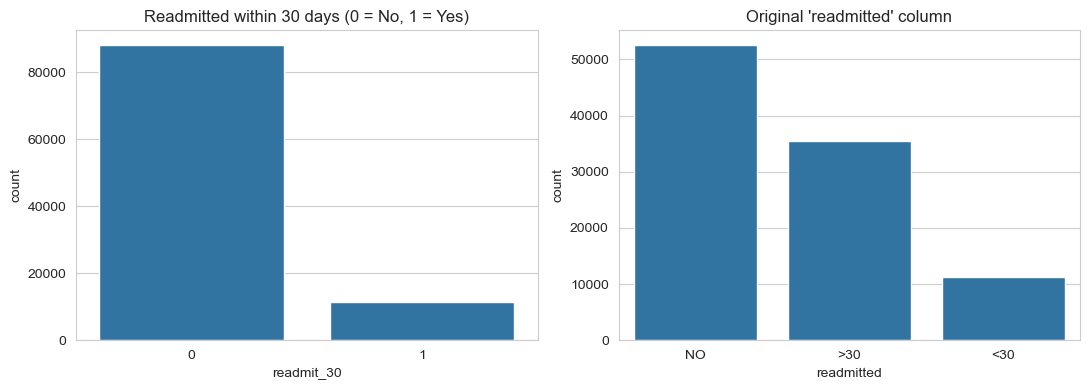

In [18]:
target_counts = df["readmit_30"].value_counts().sort_index()
majority_baseline = target_counts.max() / len(df)
print((target_counts / len(df) * 100).round(2).rename("percent"))
print(f"\nAccuracy of always predicting 'not readmitted within 30 days': {majority_baseline:.4f}")
print("-> a model must beat this using recall / F1 / ROC-AUC, not accuracy alone.")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(x="readmit_30", data=df, ax=ax[0])
ax[0].set_title("Readmitted within 30 days (0 = No, 1 = Yes)")
sns.countplot(x="readmitted", data=df, order=["NO", ">30", "<30"], ax=ax[1])
ax[1].set_title("Original 'readmitted' column")
plt.tight_layout(); plt.show()

In [19]:
enc_per_patient = df.groupby("patient_nbr").size()
print("Patients with more than one encounter: "
      f"{(enc_per_patient > 1).mean() * 100:.1f}%  (max encounters for one patient = {enc_per_patient.max()})")
print("-> repeated patients are the reason for a patient-level split.")

Patients with more than one encounter: 23.3%  (max encounters for one patient = 40)
-> repeated patients are the reason for a patient-level split.


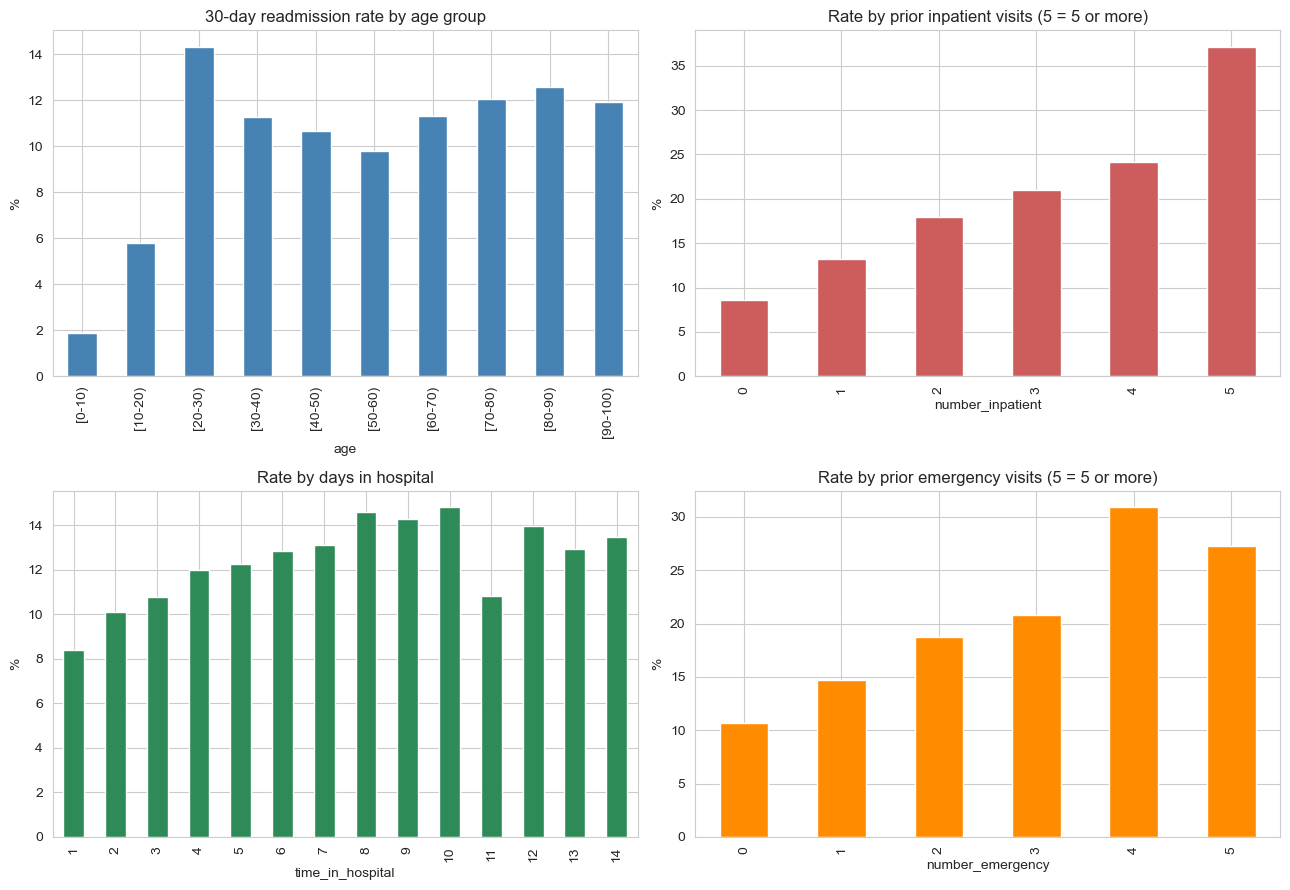

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

rate_age = df.groupby("age")["readmit_30"].mean() * 100
rate_age.plot(kind="bar", ax=axes[0, 0], color="steelblue")
axes[0, 0].set_title("30-day readmission rate by age group"); axes[0, 0].set_ylabel("%")

inp = df["number_inpatient"].clip(upper=5)
(df.groupby(inp)["readmit_30"].mean() * 100).plot(kind="bar", ax=axes[0, 1], color="indianred")
axes[0, 1].set_title("Rate by prior inpatient visits (5 = 5 or more)"); axes[0, 1].set_ylabel("%")

(df.groupby("time_in_hospital")["readmit_30"].mean() * 100).plot(kind="bar", ax=axes[1, 0], color="seagreen")
axes[1, 0].set_title("Rate by days in hospital"); axes[1, 0].set_ylabel("%")

emer = df["number_emergency"].clip(upper=5)
(df.groupby(emer)["readmit_30"].mean() * 100).plot(kind="bar", ax=axes[1, 1], color="darkorange")
axes[1, 1].set_title("Rate by prior emergency visits (5 = 5 or more)"); axes[1, 1].set_ylabel("%")
plt.tight_layout(); plt.show()

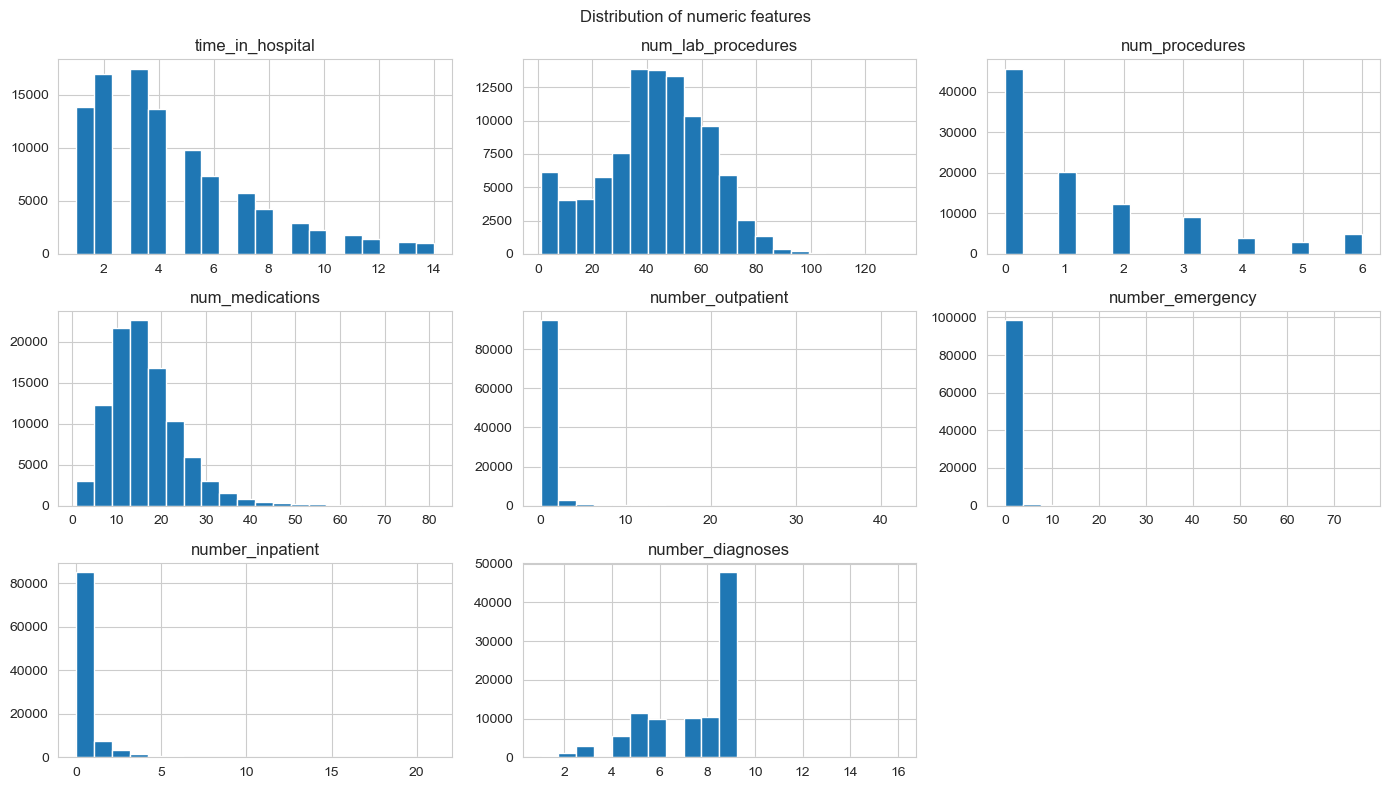

Skewness:
time_in_hospital       1.14
num_lab_procedures    -0.24
num_procedures         1.32
num_medications        1.34
number_outpatient      8.84
number_emergency      22.85
number_inpatient       3.63
number_diagnoses      -0.86
dtype: float64

The visit counts are strongly right-skewed. Trees are not affected by skew, and for Logistic Regression we scale the features.


In [21]:
numeric_eda = ["time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications",
               "number_outpatient", "number_emergency", "number_inpatient", "number_diagnoses"]

df[numeric_eda].hist(figsize=(14, 8), bins=20)
plt.suptitle("Distribution of numeric features"); plt.tight_layout(); plt.show()

print("Skewness:")
print(df[numeric_eda].skew().round(2))
print("\nThe visit counts are strongly right-skewed. Trees are not affected by skew, and for Logistic Regression we scale the features.")

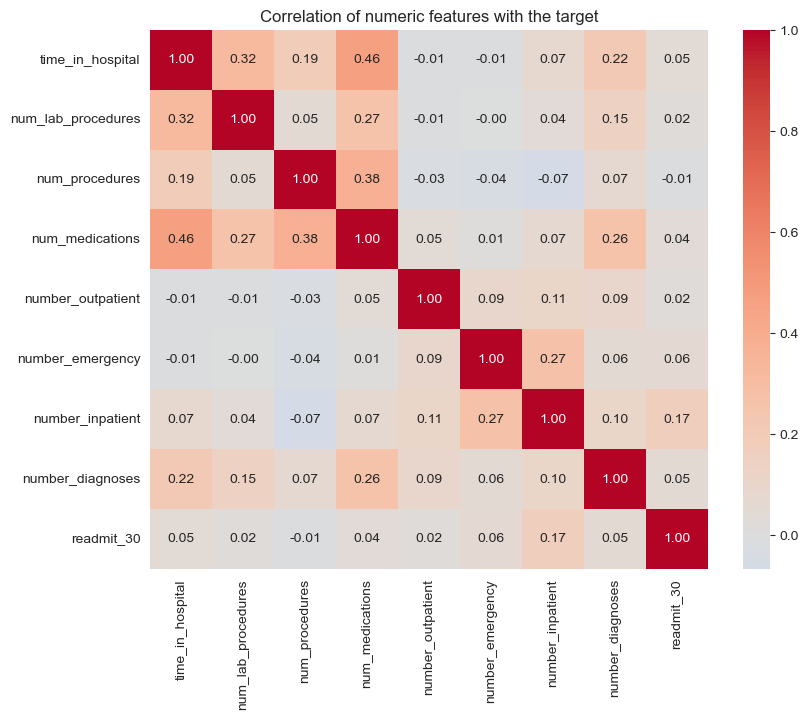

In [22]:
plt.figure(figsize=(9, 7))
sns.heatmap(df[numeric_eda + ["readmit_30"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation of numeric features with the target")
plt.show()

## 5. Feature Engineering

### 5.1 Organise the diagnosis codes
`diag_1`, `diag_2`, `diag_3` have hundreds of ICD-9 codes. We group them into broad clinical categories (the standard grouping used for this dataset):
Circulatory (390–459, 785), Respiratory (460–519, 786), Digestive (520–579, 787), Diabetes (250.xx), Injury (800–999), Musculoskeletal (710–739), Genitourinary (580–629, 788), Neoplasms (140–239), Other (everything else, including `V` and `E` codes). Missing diagnoses stay as 'Missing'.

In [23]:
def diag_to_group(code):
    code = str(code)
    if code == "Missing":
        return "Missing"
    if code.startswith(("V", "E")):
        return "Other"
    try:
        v = int(float(code))
    except ValueError:
        return "Other"
    if v == 250:                       return "Diabetes"
    if 390 <= v <= 459 or v == 785:    return "Circulatory"
    if 460 <= v <= 519 or v == 786:    return "Respiratory"
    if 520 <= v <= 579 or v == 787:    return "Digestive"
    if 800 <= v <= 999:                return "Injury"
    if 710 <= v <= 739:                return "Musculoskeletal"
    if 580 <= v <= 629 or v == 788:    return "Genitourinary"
    if 140 <= v <= 239:                return "Neoplasms"
    return "Other"

def map_diag_column(series):
    lookup = {c: diag_to_group(c) for c in series.unique()}   # map each unique code once (fast)
    return series.map(lookup)

print(map_diag_column(df["diag_1"]).value_counts())

diag_1
Circulatory        29680
Other              17793
Respiratory        13934
Digestive           9333
Diabetes            8661
Injury              6851
Genitourinary       5002
Musculoskeletal     4935
Neoplasms           3131
Missing               20
Name: count, dtype: int64


### 5.2 Use `IDS_mapping.csv` to describe the ID columns
The three `*_id` columns are codes. We translate them with the mapping file and group rare / similar meanings so the model sees a small number of meaningful categories. Codes whose description is *NULL / Not Available / Not Mapped / Unknown* become **'Unknown'**.

In [24]:
UNKNOWN_PATTERN = r"null|not available|not mapped|unknown|invalid"

def admission_type_label(desc):
    return "Unknown" if re.search(UNKNOWN_PATTERN, desc, re.I) else desc

def discharge_group_label(desc):
    if re.search(UNKNOWN_PATTERN, desc, re.I):        return "Unknown"
    if re.search(r"left ama", desc, re.I):            return "Left AMA"
    if re.search(r"home health|home iv", desc, re.I): return "Home with health service"
    if desc.strip().lower() == "discharged to home":  return "Home"
    return "Transferred / other care"

def source_group_label(desc):
    d = desc.lower()
    if re.search(UNKNOWN_PATTERN, d):   return "Unknown"
    if "referral" in d:                 return "Referral"
    if "emergency room" in d:           return "Emergency room"
    if "transfer" in d:                 return "Transfer"
    return "Other"

ADMISSION_TYPE_MAP = {i: admission_type_label(d) for i, d in id_maps["admission_type_id"].items()}
DISCHARGE_GROUP_MAP = {i: discharge_group_label(d) for i, d in id_maps["discharge_disposition_id"].items()}
SOURCE_GROUP_MAP = {i: source_group_label(d) for i, d in id_maps["admission_source_id"].items()}

print(pd.Series(DISCHARGE_GROUP_MAP).value_counts(), "\n")
print(pd.Series(SOURCE_GROUP_MAP).value_counts())

Transferred / other care    22
Unknown                      4
Home with health service     2
Home                         1
Left AMA                     1
Name: count, dtype: int64 

Transfer          8
Other             8
Unknown           5
Referral          3
Emergency room    1
Name: count, dtype: int64


### 5.3 Other engineered features
* `age_num` – midpoint of the age bracket (e.g. `[70-80)` -> 75); `age_group` is used later for subgroup analysis only.
* `total_prior_visits` – outpatient + emergency + inpatient visits in the previous year.
* `n_meds_active`, `n_meds_changed` – how many diabetes drugs are used / had their dose changed (Up/Down).
* Individual medication columns are kept only if at least 1 % of encounters use them; the rest are summarised by the two counts above.
* Rare categories of `medical_specialty` and `payer_code` are grouped into **'Other'** (frequencies are computed without using the target, so there is no leakage).

In [25]:
MED_COLUMNS = ["metformin", "repaglinide", "nateglinide", "chlorpropamide", "glimepiride", "acetohexamide",
               "glipizide", "glyburide", "tolbutamide", "pioglitazone", "rosiglitazone", "acarbose", "miglitol",
               "troglitazone", "tolazamide", "insulin", "glyburide-metformin", "glipizide-metformin",
               "glimepiride-pioglitazone", "metformin-rosiglitazone", "metformin-pioglitazone"]
MED_COLUMNS = [c for c in MED_COLUMNS if c in df.columns]

KEEP_MEDS = [c for c in MED_COLUMNS if (df[c] != "No").mean() >= 0.01]
TOP_SPECIALTIES = df["medical_specialty"].value_counts().drop("Unknown", errors="ignore").head(10).index.tolist()
TOP_PAYERS = df["payer_code"].value_counts().drop("Unknown", errors="ignore").head(8).index.tolist()

AGE_MIDPOINT = {f"[{a}-{a + 10})": a + 5 for a in range(0, 100, 10)}

print("Medications kept as individual features:", KEEP_MEDS)
print("Top specialties:", TOP_SPECIALTIES)
print("Top payers     :", TOP_PAYERS)

Medications kept as individual features: ['metformin', 'repaglinide', 'glimepiride', 'glipizide', 'glyburide', 'pioglitazone', 'rosiglitazone', 'insulin']
Top specialties: ['InternalMedicine', 'Emergency/Trauma', 'Family/GeneralPractice', 'Cardiology', 'Surgery-General', 'Nephrology', 'Orthopedics', 'Orthopedics-Reconstructive', 'Radiologist', 'Pulmonology']
Top payers     : ['MC', 'HM', 'SP', 'BC', 'MD', 'CP', 'UN', 'CM']


In [26]:
def engineer_features(d):
    d = d.copy()
    # age
    d["age_num"] = d["age"].map(AGE_MIDPOINT)
    d["age_group"] = pd.cut(d["age_num"], bins=[0, 30, 50, 70, 80, 100],
                            labels=["<30", "30-49", "50-69", "70-79", "80+"]).astype(str)
    # prior utilisation
    d["total_prior_visits"] = d[["number_outpatient", "number_emergency", "number_inpatient"]].sum(axis=1)
    d["prior_inpatient_bucket"] = d["number_inpatient"].clip(upper=2).map({0: "0", 1: "1", 2: "2+"})
    # diagnoses
    for c in ["diag_1", "diag_2", "diag_3"]:
        d[c + "_group"] = map_diag_column(d[c])
    # ID columns described through IDS_mapping.csv
    d["admission_type"] = d["admission_type_id"].map(ADMISSION_TYPE_MAP).fillna("Unknown")
    d["discharge_group"] = d["discharge_disposition_id"].map(DISCHARGE_GROUP_MAP).fillna("Unknown")
    d["admission_source_group"] = d["admission_source_id"].map(SOURCE_GROUP_MAP).fillna("Unknown")
    # rare categories -> Other
    d["medical_specialty_grp"] = d["medical_specialty"].where(
        d["medical_specialty"].isin(TOP_SPECIALTIES + ["Unknown"]), "Other")
    d["payer_code_grp"] = d["payer_code"].where(d["payer_code"].isin(TOP_PAYERS + ["Unknown"]), "Other")
    # medications
    d["n_meds_active"] = (d[MED_COLUMNS] != "No").sum(axis=1)
    d["n_meds_changed"] = d[MED_COLUMNS].isin(["Up", "Down"]).sum(axis=1)
    return d

df_model = engineer_features(df)
df_model[["age", "age_num", "age_group", "diag_1", "diag_1_group", "discharge_disposition_id",
          "discharge_group", "total_prior_visits", "n_meds_active", "n_meds_changed"]].head()

,age,age_num,age_group,diag_1,diag_1_group,discharge_disposition_id,discharge_group,total_prior_visits,n_meds_active,n_meds_changed
0,[0-10),5,<30,250.83,Diabetes,25,Unknown,0,0,0
1,[10-20),15,<30,276,Other,1,Home,0,1,1
2,[20-30),25,<30,648,Other,1,Home,3,1,0
3,[30-40),35,30-49,8,Other,1,Home,0,1,1
4,[40-50),45,30-49,197,Neoplasms,1,Home,0,2,0


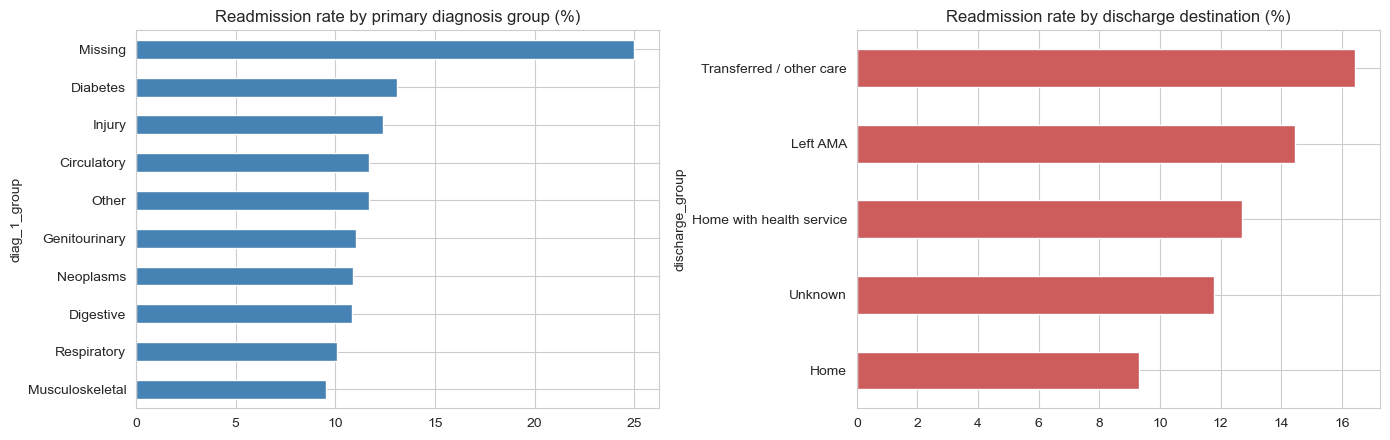

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
(df_model.groupby("diag_1_group")["readmit_30"].mean().sort_values() * 100).plot(kind="barh", ax=axes[0], color="steelblue")
axes[0].set_title("Readmission rate by primary diagnosis group (%)")
(df_model.groupby("discharge_group")["readmit_30"].mean().sort_values() * 100).plot(kind="barh", ax=axes[1], color="indianred")
axes[1].set_title("Readmission rate by discharge destination (%)")
plt.tight_layout(); plt.show()

### 5.4 Select the final features
`encounter_id`, `patient_nbr` and the raw ID / code columns are excluded.

**`race` is deliberately not used as a model input.** It is kept in the table only to *audit* whether the model performs fairly across racial groups (Section 9.6). To include it, add `"race"` to `CATEGORICAL_FEATURES`.

In [28]:
NUMERIC_FEATURES = ["age_num", "time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications",
                    "number_outpatient", "number_emergency", "number_inpatient", "number_diagnoses",
                    "total_prior_visits", "n_meds_active", "n_meds_changed"]

CATEGORICAL_FEATURES = (["gender", "admission_type", "admission_source_group", "discharge_group",
                         "medical_specialty_grp", "payer_code_grp", "max_glu_serum", "A1Cresult",
                         "change", "diabetesMed", "diag_1_group", "diag_2_group", "diag_3_group"]
                        + KEEP_MEDS)

FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES
print(f"{len(NUMERIC_FEATURES)} numeric + {len(CATEGORICAL_FEATURES)} categorical = {len(FEATURES)} input features")
print("Missing values in features:", int(df_model[FEATURES].isnull().sum().sum()))

12 numeric + 21 categorical = 33 input features
Missing values in features: 0


## 6. Model Selection
PS18 asks for three algorithms:

| Model | Why | Preprocessing |
|---|---|---|
| **Logistic Regression** | simple, interpretable baseline; gives direct probabilities | one-hot + **StandardScaler** |
| **Decision Tree** | easy-to-read rules | one-hot (no scaling needed) |
| **Random Forest** | many trees, usually the strongest and most stable | one-hot (no scaling needed) |

All three use `class_weight='balanced'` to handle the class imbalance. Preprocessing is wrapped in a scikit-learn **Pipeline** with a `ColumnTransformer`, so the saved model accepts raw feature columns and the scaler / encoder are fitted on training data only.

## 7. Model Training

### 7.1 Primary cohort: retain encounters, split by patient

The primary analysis retains **all eligible encounters** rather than keeping only each patient's first encounter. This choice uses the longitudinal information available in the dataset: prior utilisation and encounter history are informative predictors, and discarding repeat encounters would remove a substantial amount of data.

The trade-off is that repeat encounters from one patient are correlated. A random row-level split would let a patient's records appear in both training and test sets and could produce optimistic results. Therefore, the primary analysis uses `GroupShuffleSplit` with `patient_nbr`, and grouped cross-validation (`GroupKFold`) during tuning. Every encounter for a patient stays in one partition.

The supplied three-week learning guide describes a simpler **first-encounter-per-patient** cohort. That is a valid alternative estimand (one record per person, rather than one record per eligible encounter). To make the choice transparent, Section 7.2 performs a sensitivity comparison using that first-encounter cohort. The primary all-encounter result remains the main result because it preserves the encounter-level prediction task while controlling patient leakage.

In [29]:
X = df_model[FEATURES]
y = df_model["readmit_30"]
groups = df_model["patient_nbr"]

gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=RANDOM_STATE)
train_idx, test_idx = next(gss.split(X, y, groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
g_train = groups.iloc[train_idx]

overlap = set(groups.iloc[train_idx]) & set(groups.iloc[test_idx])
assert len(overlap) == 0, "Patient leakage between train and test!"

print("Training data:", X_train.shape, "| patients:", g_train.nunique())
print("Testing data :", X_test.shape, "| patients:", groups.iloc[test_idx].nunique())
print("Patients in both sets:", len(overlap))
print(f"\nReadmission rate - train: {y_train.mean():.4f} | test: {y_test.mean():.4f}")

Training data: (79567, 33) | patients: 55989
Testing data : (19773, 33) | patients: 13998
Patients in both sets: 0

Readmission rate - train: 0.1140 | test: 0.1135


### 7.2 Build pipelines and train the three baseline models

In [30]:
def make_preprocessor(scale):
    numeric_step = StandardScaler() if scale else "passthrough"
    return ColumnTransformer([
        ("num", numeric_step, NUMERIC_FEATURES),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL_FEATURES),
    ])

def make_lr(**kw):
    return Pipeline([("prep", make_preprocessor(True)),
                     ("clf", LogisticRegression(max_iter=1000, class_weight="balanced",
                                                random_state=RANDOM_STATE, **kw))])

def make_dt(**kw):
    kw.setdefault("criterion", "entropy")
    return Pipeline([("prep", make_preprocessor(False)),
                     ("clf", DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE, **kw))])

def make_rf(n_jobs=-1, **kw):
    kw.setdefault("n_estimators", 100)
    return Pipeline([("prep", make_preprocessor(False)),
                     ("clf", RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE,
                                                    n_jobs=n_jobs, **kw))])

baseline_models = {
    "Logistic Regression": make_lr(),
    "Decision Tree": make_dt(),          # no depth limit -> expected to overfit
    "Random Forest": make_rf(),
}

for name, model in baseline_models.items():
    t0 = time.time()
    model.fit(X_train, y_train)
    print(f"{name} trained successfully in {time.time() - t0:.1f}s")

Logistic Regression trained successfully in 2.5s
Decision Tree trained successfully in 5.0s
Random Forest trained successfully in 5.8s


## 8. Model Evaluation

We report **Accuracy, Precision, Recall, F1-score, ROC-AUC** (and PR-AUC) on the unseen test patients. Precision, recall and F1 are for the positive class (*readmitted within 30 days*) at the default 0.5 probability cut-off. ROC-AUC and PR-AUC do not depend on a cut-off. The train ROC-AUC column exposes overfitting.

In [31]:
def evaluate_model(name, model, X_tr, y_tr, X_te, y_te, threshold=0.5):
    p_tr = model.predict_proba(X_tr)[:, 1]
    p_te = model.predict_proba(X_te)[:, 1]
    pred = (p_te >= threshold).astype(int)
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_te, pred),
        "Precision": precision_score(y_te, pred, zero_division=0),
        "Recall": recall_score(y_te, pred, zero_division=0),
        "F1-score": f1_score(y_te, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_te, p_te),
        "PR-AUC": average_precision_score(y_te, p_te),
        "Train ROC-AUC": roc_auc_score(y_tr, p_tr),
    }

baseline_results = pd.DataFrame([
    evaluate_model(n, m, X_train, y_train, X_test, y_test) for n, m in baseline_models.items()
]).set_index("Model").round(4)

print("Always-predict-'No' accuracy:", round(1 - y_test.mean(), 4), "(PR-AUC of a random model =", round(y_test.mean(), 4), ")")
baseline_results

Always-predict-'No' accuracy: 0.8865 (PR-AUC of a random model = 0.1135 )


,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC,Train ROC-AUC
Model,,,,,,,
Logistic Regression,0.6587,0.1795,0.5619,0.2721,0.6644,0.2138,0.6626
Decision Tree,0.7976,0.1478,0.1644,0.1557,0.5215,0.1191,1.0000
Random Forest,0.8866,0.5714,0.0018,0.0036,0.6548,0.2018,1.0000


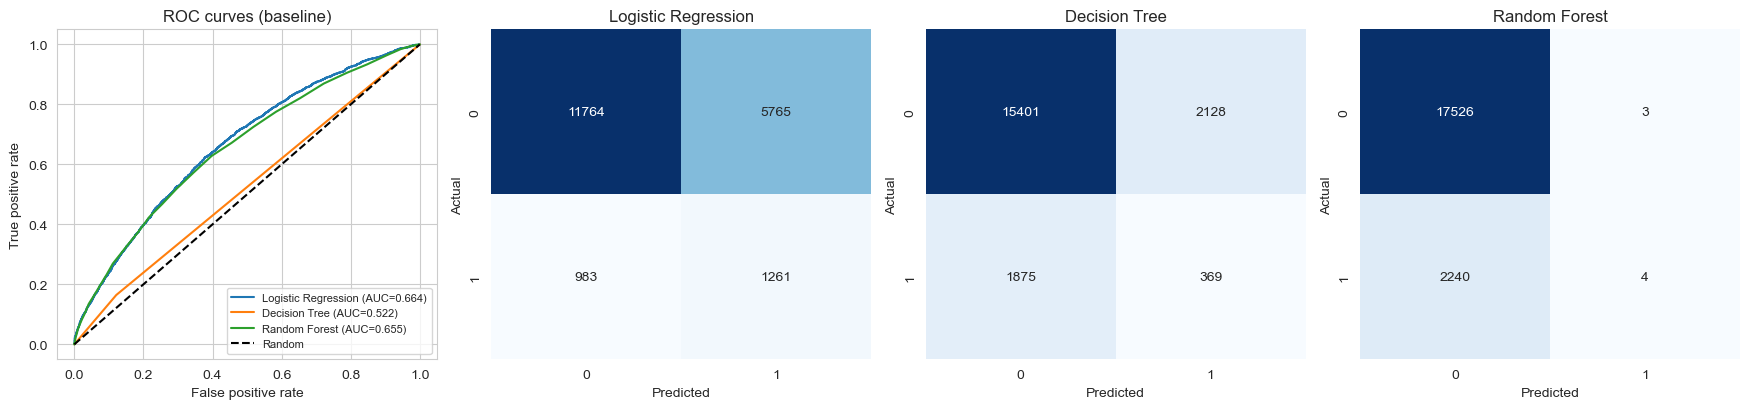

In [32]:
def plot_roc_and_confusion(models, X_te, y_te, title_suffix=""):
    fig, axes = plt.subplots(1, 1 + len(models), figsize=(5 + 4.2 * len(models), 4.2))
    for name, m in models.items():
        fpr, tpr, _ = roc_curve(y_te, m.predict_proba(X_te)[:, 1])
        axes[0].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_te, m.predict_proba(X_te)[:, 1]):.3f})")
    axes[0].plot([0, 1], [0, 1], "k--", label="Random")
    axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate")
    axes[0].set_title("ROC curves" + title_suffix); axes[0].legend(loc="lower right", fontsize=8)
    for ax, (name, m) in zip(axes[1:], models.items()):
        cm = confusion_matrix(y_te, m.predict(X_te))
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
        ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title(name)
    plt.tight_layout(); plt.show()

plot_roc_and_confusion(baseline_models, X_test, y_test, " (baseline)")

In [33]:
for name, m in baseline_models.items():
    print("=" * 60); print(name); print("=" * 60)
    print(classification_report(y_test, m.predict(X_test), target_names=["Not readmitted", "Readmitted <30d"], zero_division=0))

Logistic Regression
                 precision    recall  f1-score   support

 Not readmitted       0.92      0.67      0.78     17529
Readmitted <30d       0.18      0.56      0.27      2244

       accuracy                           0.66     19773
      macro avg       0.55      0.62      0.52     19773
   weighted avg       0.84      0.66      0.72     19773

Decision Tree
                 precision    recall  f1-score   support

 Not readmitted       0.89      0.88      0.88     17529
Readmitted <30d       0.15      0.16      0.16      2244

       accuracy                           0.80     19773
      macro avg       0.52      0.52      0.52     19773
   weighted avg       0.81      0.80      0.80     19773

Random Forest
                 precision    recall  f1-score   support

 Not readmitted       0.89      1.00      0.94     17529
Readmitted <30d       0.57      0.00      0.00      2244

       accuracy                           0.89     19773
      macro avg       0.73      

**How to read this:** the unrestricted Decision Tree typically shows a train ROC-AUC far above its test ROC-AUC (overfitting). With balanced class weights the models catch many readmissions (high recall) at the cost of precision and accuracy; that is the expected trade-off on imbalanced data. Next we tune the models.

## 9. Hyperparameter Tuning

### 9.1 Grid search with patient-grouped cross-validation
`GridSearchCV` with **`GroupKFold`** makes sure that a patient never appears in both the training and validation folds. The scoring metric is **ROC-AUC**, which suits imbalanced data. Grids are kept small so the notebook runs in reasonable time.

In [34]:
cv = GroupKFold(n_splits=3)

searches = {
    "Logistic Regression": GridSearchCV(
        make_lr(), {"clf__C": [0.001, 0.01, 0.1, 1]},
        cv=cv, scoring="roc_auc", n_jobs=-1, return_train_score=True),
    "Decision Tree": GridSearchCV(
        make_dt(), {"clf__max_depth": [3, 5, 7, 10], "clf__min_samples_leaf": [20, 50, 100],
                    "clf__criterion": ["gini", "entropy"]},
        cv=cv, scoring="roc_auc", n_jobs=-1, return_train_score=True),
    "Random Forest": GridSearchCV(
        make_rf(n_jobs=1), {"clf__n_estimators": [200], "clf__max_depth": [8, 12, 16],
                            "clf__min_samples_leaf": [10, 20, 50]},
        cv=cv, scoring="roc_auc", n_jobs=-1, return_train_score=True),
}

for name, gs in searches.items():
    t0 = time.time()
    gs.fit(X_train, y_train, groups=g_train)
    print(f"{name}\n  Best parameters : {gs.best_params_}\n  Best CV ROC-AUC : {gs.best_score_:.4f}  ({time.time() - t0:.0f}s)\n")

Logistic Regression
  Best parameters : {'clf__C': 0.001}
  Best CV ROC-AUC : 0.6579  (21s)

Decision Tree
  Best parameters : {'clf__criterion': 'gini', 'clf__max_depth': 5, 'clf__min_samples_leaf': 100}
  Best CV ROC-AUC : 0.6496  (41s)

Random Forest
  Best parameters : {'clf__max_depth': 12, 'clf__min_samples_leaf': 20, 'clf__n_estimators': 200}
  Best CV ROC-AUC : 0.6666  (343s)



### 9.2 Effect of tree depth (overfitting check)

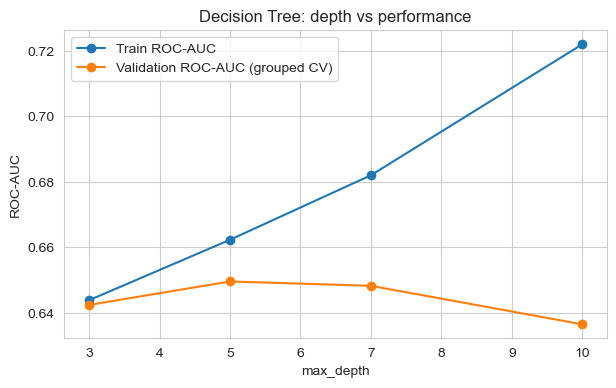

In [35]:
cvr = pd.DataFrame(searches["Decision Tree"].cv_results_)
depth_curve = cvr.groupby("param_clf__max_depth")[["mean_train_score", "mean_test_score"]].max()

plt.figure(figsize=(7, 4))
plt.plot(depth_curve.index.astype(int), depth_curve["mean_train_score"], marker="o", label="Train ROC-AUC")
plt.plot(depth_curve.index.astype(int), depth_curve["mean_test_score"], marker="o", label="Validation ROC-AUC (grouped CV)")
plt.xlabel("max_depth"); plt.ylabel("ROC-AUC"); plt.title("Decision Tree: depth vs performance")
plt.legend(); plt.show()

### 9.3 Tuned models on the test set

In [36]:
tuned_models = {name: gs.best_estimator_ for name, gs in searches.items()}

tuned_results = pd.DataFrame([
    evaluate_model(n, m, X_train, y_train, X_test, y_test) for n, m in tuned_models.items()
]).set_index("Model").round(4)

print("Tuned models:")
display(tuned_results)

compare = pd.concat({"Baseline": baseline_results[["F1-score", "ROC-AUC"]],
                     "Tuned": tuned_results[["F1-score", "ROC-AUC"]]}, axis=1)
print("Baseline vs tuned:")
display(compare)

Tuned models:


,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC,Train ROC-AUC
Model,,,,,,,
Logistic Regression,0.6622,0.1800,0.5557,0.2719,0.6653,0.2137,0.6619
Decision Tree,0.6344,0.1730,0.5878,0.2674,0.6557,0.2022,0.6592
Random Forest,0.6811,0.1899,0.5544,0.2829,0.6756,0.2226,0.7539


Baseline vs tuned:


Baseline            Tuned        
                    F1-score ROC-AUC F1-score ROC-AUC
Model                                                
Logistic Regression   0.2721  0.6644   0.2719  0.6653
Decision Tree         0.1557  0.5215   0.2674  0.6557
Random Forest         0.0036  0.6548   0.2829  0.6756

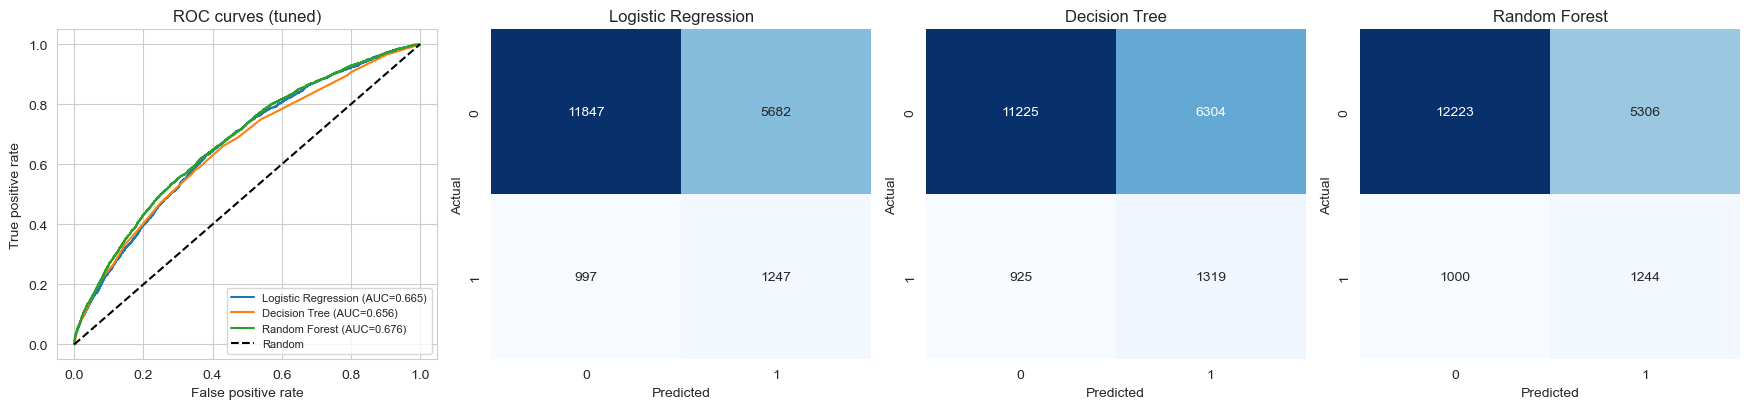

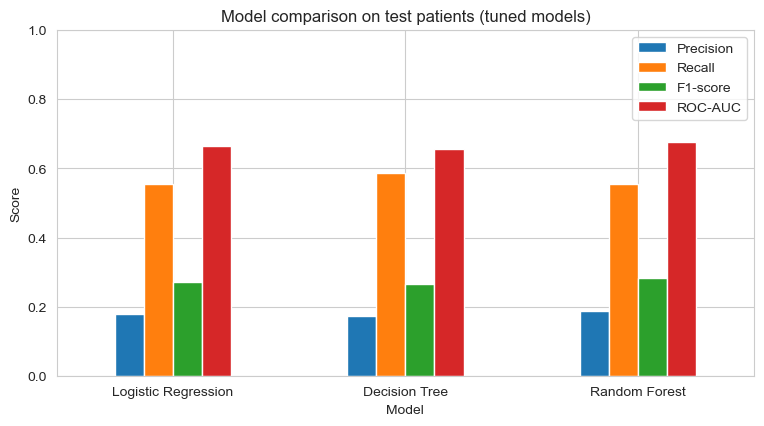

Best model by grouped cross-validation ROC-AUC (chosen without looking at the test set): Random Forest


In [37]:
plot_roc_and_confusion(tuned_models, X_test, y_test, " (tuned)")

metrics_to_plot = ["Precision", "Recall", "F1-score", "ROC-AUC"]
tuned_results[metrics_to_plot].plot(kind="bar", figsize=(9, 4.5), rot=0)
plt.title("Model comparison on test patients (tuned models)"); plt.ylabel("Score"); plt.ylim(0, 1)
plt.legend(loc="upper right"); plt.show()

best_name = max(searches, key=lambda k: searches[k].best_score_)
print(f"Best model by grouped cross-validation ROC-AUC (chosen without looking at the test set): {best_name}")

### 7.2 Sensitivity analysis: first encounter per patient versus all eligible encounters

The learning guide's first-encounter approach and the primary grouped all-encounter approach answer slightly different questions. This sensitivity analysis applies the already-selected best model configuration to a first-encounter-only cohort, then compares ROC-AUC and PR-AUC with the primary held-out encounter test set. The first-encounter cohort uses a stratified patient-level split because it contains one row per patient. To keep the sensitivity check focused, it reuses the best hyperparameter configuration selected by grouped CV on the primary cohort rather than conducting a second independent grid search. No test data are used to fit either model.

**Interpretation caution:** the cohorts have different sizes and event prevalence, so this is a robustness/context comparison, not a perfectly matched experiment. Compare ranking metrics (ROC-AUC and PR-AUC) alongside cohort size and prevalence; do not interpret small differences as proof that one cohort strategy is universally better.

In [38]:

from sklearn.model_selection import train_test_split

# First encounter = earliest encounter_id in the supplied encounter ordering.
# This mirrors the learning-guide simplification while retaining the same eligibility rules.
first_encounter_df = (
    df_model.sort_values("encounter_id")
            .drop_duplicates(subset="patient_nbr", keep="first")
            .reset_index(drop=True)
)

X_first = first_encounter_df[FEATURES]
y_first = first_encounter_df["readmit_30"]

X_first_train, X_first_test, y_first_train, y_first_test = train_test_split(
    X_first, y_first, test_size=0.20, random_state=RANDOM_STATE,
    stratify=y_first
)

# Reuse the best hyperparameters selected by grouped CV on the primary training cohort.
first_model = clone(searches[best_name].best_estimator_)
first_model.fit(X_first_train, y_first_train)
first_prob = first_model.predict_proba(X_first_test)[:, 1]

primary_row = tuned_results.loc[best_name]
cohort_sensitivity = pd.DataFrame([
    {
        "Cohort": "All eligible encounters (patient-grouped split)",
        "Rows": len(df_model),
        "Unique patients": df_model["patient_nbr"].nunique(),
        "Test rows": len(X_test),
        "Test readmission rate": float(y_test.mean()),
        "ROC-AUC": float(primary_row["ROC-AUC"]),
        "PR-AUC": float(primary_row["PR-AUC"]),
    },
    {
        "Cohort": "First encounter per patient (stratified split)",
        "Rows": len(first_encounter_df),
        "Unique patients": first_encounter_df["patient_nbr"].nunique(),
        "Test rows": len(X_first_test),
        "Test readmission rate": float(y_first_test.mean()),
        "ROC-AUC": roc_auc_score(y_first_test, first_prob),
        "PR-AUC": average_precision_score(y_first_test, first_prob),
    }
]).set_index("Cohort")

display(cohort_sensitivity.round(4))
print(
    "The first-encounter estimate represents one initial eligible encounter per patient; "
    "the grouped all-encounter estimate represents eligible encounters for unseen patients."
)


,Rows,Unique patients,Test rows,Test readmission rate,ROC-AUC,PR-AUC
Cohort,,,,,,
All eligible encounters (patient-grouped split),99340,69987,19773,0.1135,0.6756,0.2226
First encounter per patient (stratified split),69987,69987,13998,0.0898,0.6554,0.1652


The first-encounter estimate represents one initial eligible encounter per patient; the grouped all-encounter estimate represents eligible encounters for unseen patients.


### 9.4 Group-aware sigmoid calibration and threshold selection

This section combines the strengths of both notebooks: Sohan's cross-validated sigmoid calibration and PS18's patient-level leakage protection.

**Why group-aware calibration matters:** the primary cohort contains repeated encounters. Ordinary stratified folds can place encounters from the same patient in both the calibration-training and calibration-validation folds. We therefore construct every calibration fold with `GroupKFold` and `patient_nbr`.

Workflow:

1. Fit the selected, tuned pipeline inside a `CalibratedClassifierCV` ensemble using five patient-grouped folds.
2. Generate out-of-fold calibrated probabilities for every training encounter using an outer patient-grouped loop. Each outer validation patient's records are excluded from both the base estimator and its calibration fit.
3. Select two candidate operating thresholds from those out-of-fold probabilities: (a) the threshold that maximises F1, and (b) the 80th percentile, which flags approximately the highest-risk 20% of training encounters.
4. Fit the final group-calibrated ensemble on all training encounters using patient-grouped folds.
5. Evaluate calibrated probabilities and both thresholds once on the untouched patient-grouped test set.

**Why this differs from the original PS18 calibration:** the original Platt approach reserved 25% of training patients for calibration and left the base model fitted on the remaining 75%. This hybrid approach uses group-aware cross-validation to learn calibration and returns an ensemble of fold-specific estimators. It uses the training data more efficiently, while preserving the patient separation requirement.

**Important:** the outer out-of-fold probabilities are used only to select thresholds. The test set is not used to fit the calibrator or select thresholds. The 20% threshold is a capacity-based policy; the F1 threshold is a metric-based policy. Report both rather than assuming one is universally best.


In [39]:
from sklearn.calibration import CalibratedClassifierCV

# Build patient-grouped folds for the final calibrated ensemble.
inner_group_cv = GroupKFold(n_splits=5)
calibration_splits = list(inner_group_cv.split(X_train, y_train, groups=g_train))

final_base_estimator = clone(searches[best_name].best_estimator_)
calibrated_model = CalibratedClassifierCV(
    estimator=final_base_estimator,
    method="sigmoid",
    cv=calibration_splits
)
calibrated_model.fit(X_train, y_train)

# Nested, group-aware out-of-fold predictions for threshold selection.
# Each outer validation fold is unseen by both the base estimator and calibrator.
outer_group_cv = GroupKFold(n_splits=5)
oof_calibrated = np.zeros(len(X_train), dtype=float)

for fold, (outer_fit_idx, outer_val_idx) in enumerate(
    outer_group_cv.split(X_train, y_train, groups=g_train), start=1
):
    X_outer_fit = X_train.iloc[outer_fit_idx]
    y_outer_fit = y_train.iloc[outer_fit_idx]
    groups_outer_fit = g_train.iloc[outer_fit_idx]

    inner_cv_outer = GroupKFold(n_splits=4)
    inner_splits_outer = list(
        inner_cv_outer.split(X_outer_fit, y_outer_fit, groups=groups_outer_fit)
    )

    fold_calibrator = CalibratedClassifierCV(
        estimator=clone(searches[best_name].best_estimator_),
        method="sigmoid",
        cv=inner_splits_outer
    )
    fold_calibrator.fit(X_outer_fit, y_outer_fit)
    oof_calibrated[outer_val_idx] = fold_calibrator.predict_proba(
        X_train.iloc[outer_val_idx]
    )[:, 1]
    print(f"Completed outer patient-grouped fold {fold}/5")

# Candidate A: threshold maximising F1 on out-of-fold training predictions.
oof_precision, oof_recall, oof_thresholds = precision_recall_curve(
    y_train, oof_calibrated
)
oof_f1 = (
    2 * oof_precision[:-1] * oof_recall[:-1]
    / (oof_precision[:-1] + oof_recall[:-1] + 1e-12)
)
F1_THRESHOLD = float(oof_thresholds[np.argmax(oof_f1)])

# Candidate B: capacity-based policy that flags the highest-risk 20%.
TOP20_THRESHOLD = float(np.quantile(oof_calibrated, 0.80))

# Keep F1 as the primary threshold; report top-20% as an operational alternative.
BEST_THRESHOLD = F1_THRESHOLD
BASE_RATE = float(y_train.mean())

print(f"Selected model             : {best_name}")
print(f"Group-calibrated ensemble  : 5 folds")
print(f"OOF F1 threshold           : {F1_THRESHOLD:.4f} (OOF F1={oof_f1.max():.4f})")
print(f"OOF top-20% threshold      : {TOP20_THRESHOLD:.4f}")
print(f"Training readmission rate  : {BASE_RATE:.4f}")


Completed outer patient-grouped fold 1/5
Completed outer patient-grouped fold 2/5
Completed outer patient-grouped fold 3/5
Completed outer patient-grouped fold 4/5
Completed outer patient-grouped fold 5/5
Selected model             : Random Forest
Group-calibrated ensemble  : 5 folds
OOF F1 threshold           : 0.1415 (OOF F1=0.2794)
OOF top-20% threshold      : 0.1643
Training readmission rate  : 0.1140


Brier score (lower is better):
  constant training base rate : 0.1006
  group-calibrated model      : 0.0960


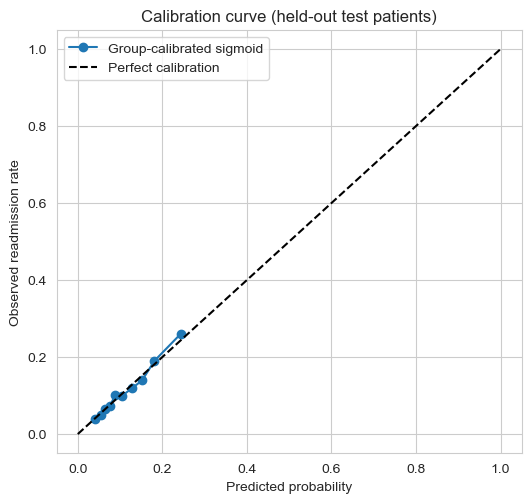

,Policy,Threshold,Flagged proportion,Precision,Recall,F1
0,F1-maximising OOF threshold,0.1415,0.2935,0.1990,0.5147,0.2871
1,Top-20%-capacity OOF threshold,0.1643,0.2023,0.2252,0.4015,0.2886


In [40]:
# Evaluate the calibrated ensemble on the untouched test patients.
test_cal = calibrated_model.predict_proba(X_test)[:, 1]

print("Brier score (lower is better):")
print(f"  constant training base rate : {brier_score_loss(y_test, np.full(len(y_test), BASE_RATE)):.4f}")
print(f"  group-calibrated model      : {brier_score_loss(y_test, test_cal):.4f}")

plt.figure(figsize=(6, 5.5))
frac_pos, mean_pred = calibration_curve(y_test, test_cal, n_bins=10, strategy="quantile")
plt.plot(mean_pred, frac_pos, marker="o", label="Group-calibrated sigmoid")
plt.plot([0, 1], [0, 1], "k--", label="Perfect calibration")
plt.xlabel("Predicted probability")
plt.ylabel("Observed readmission rate")
plt.title("Calibration curve (held-out test patients)")
plt.legend()
plt.show()

# Show the two threshold policies side by side on the same locked test set.
threshold_comparison = []
for policy, threshold in [
    ("F1-maximising OOF threshold", F1_THRESHOLD),
    ("Top-20%-capacity OOF threshold", TOP20_THRESHOLD)
]:
    pred = (test_cal >= threshold).astype(int)
    threshold_comparison.append({
        "Policy": policy,
        "Threshold": threshold,
        "Flagged proportion": pred.mean(),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0)
    })

threshold_comparison_df = pd.DataFrame(threshold_comparison)
display(threshold_comparison_df.round(4))


FINAL GROUP-CALIBRATED MODEL on unseen test patients
Model               Random Forest (group-calibrated sigmoid)
Threshold policy           F1-maximising patient-grouped OOF
Threshold                                             0.1415
Accuracy                                              0.7099
Precision                                              0.199
Recall                                                0.5147
F1-score                                              0.2871
ROC-AUC                                               0.6766
PR-AUC                                                0.2227
Brier                                                  0.096


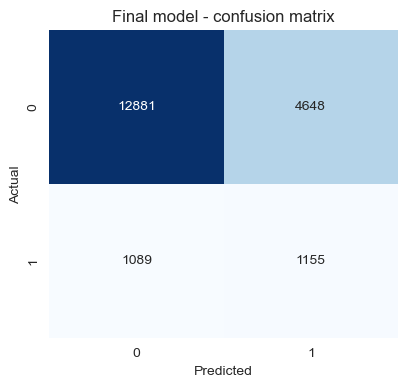

In [41]:
pred_final = (test_cal >= BEST_THRESHOLD).astype(int)
final_metrics = {
    "Model": best_name + " (group-calibrated sigmoid)",
    "Threshold policy": "F1-maximising patient-grouped OOF",
    "Threshold": BEST_THRESHOLD,
    "Accuracy": accuracy_score(y_test, pred_final),
    "Precision": precision_score(y_test, pred_final, zero_division=0),
    "Recall": recall_score(y_test, pred_final, zero_division=0),
    "F1-score": f1_score(y_test, pred_final, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, test_cal),
    "PR-AUC": average_precision_score(y_test, test_cal),
    "Brier": brier_score_loss(y_test, test_cal),
}
print("FINAL GROUP-CALIBRATED MODEL on unseen test patients")
print(pd.Series({k: (round(v, 4) if isinstance(v, (float, np.floating)) else v)
                 for k, v in final_metrics.items()}).to_string())

plt.figure(figsize=(4.5, 4))
sns.heatmap(confusion_matrix(y_test, pred_final), annot=True, fmt="d",
            cmap="Blues", cbar=False)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Final model - confusion matrix")
plt.show()


**Risk bands** (used later by the dashboard): *Low* = below the base readmission rate, *Medium* = between the base rate and the decision threshold, *High* = at or above the threshold. The table checks that the bands really separate patients.

In [42]:
LOW_CUT = min(BASE_RATE, BEST_THRESHOLD)

def risk_band(p):
    return np.where(p >= BEST_THRESHOLD, "High", np.where(p >= LOW_CUT, "Medium", "Low"))

band_check = pd.DataFrame({"band": risk_band(test_cal), "readmitted": y_test.values, "risk": test_cal})
band_summary = (band_check.groupby("band")
                .agg(patients=("readmitted", "size"), observed_rate=("readmitted", "mean"), mean_predicted=("risk", "mean"))
                .reindex(["Low", "Medium", "High"]).round(3))
band_summary

,patients,observed_rate,mean_predicted
band,,,
Low,11737,0.071,0.071
Medium,2233,0.116,0.128
High,5803,0.199,0.193


### 9.5 Contributing factors (what drives higher predicted risk?)
Two complementary views for the final group-calibrated model:
1. **Permutation importance** – how much the test ROC-AUC drops when one original variable is shuffled (ranks *importance*).
2. **Logistic Regression coefficients** – the *direction*: an odds ratio above 1 means higher risk (numeric features are standardised, so the ratio is per 1 standard deviation; categories are compared with the average of their variable).

Top 15 variables (drop in ROC-AUC when shuffled):


,feature,importance,std
1,discharge_group,0.0453,0.0023
2,number_inpatient,0.0270,0.0044
3,total_prior_visits,0.0155,0.0049
4,diag_1_group,0.0048,0.0006
5,payer_code_grp,0.0030,0.0008
6,diabetesMed,0.0024,0.0006
7,diag_2_group,0.0021,0.0004
8,time_in_hospital,0.0021,0.0005
9,metformin,0.0019,0.0008
10,admission_source_group,0.0015,0.0005


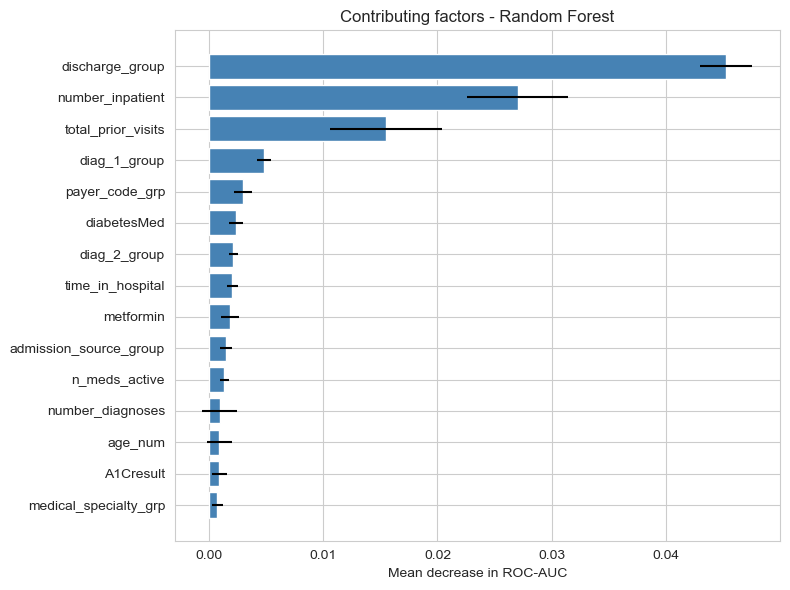

In [43]:
sample = X_test.sample(n=min(8000, len(X_test)), random_state=RANDOM_STATE)
perm = permutation_importance(calibrated_model, sample, y_test.loc[sample.index], scoring="roc_auc",
                              n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)

importance_df = (pd.DataFrame({"feature": FEATURES, "importance": perm.importances_mean, "std": perm.importances_std})
                 .sort_values("importance", ascending=False).reset_index(drop=True))
importance_df.index += 1
print("Top 15 variables (drop in ROC-AUC when shuffled):")
display(importance_df.head(15).round(4))

top = importance_df.head(15).iloc[::-1]
plt.figure(figsize=(8, 6))
plt.barh(top["feature"], top["importance"], xerr=top["std"], color="steelblue")
plt.xlabel("Mean decrease in ROC-AUC"); plt.title(f"Contributing factors - {best_name}")
plt.tight_layout(); plt.show()

In [44]:
lr_pipe = tuned_models["Logistic Regression"]
names = [n.split("__", 1)[1] for n in lr_pipe.named_steps["prep"].get_feature_names_out()]
coefs = lr_pipe.named_steps["clf"].coef_[0]
coef_df = pd.DataFrame({"feature": names, "coefficient": coefs, "odds_ratio": np.exp(coefs)})

print("Strongest factors INCREASING predicted risk (Logistic Regression):")
display(coef_df.sort_values("coefficient", ascending=False).head(10).round(3).reset_index(drop=True))
print("Strongest factors DECREASING predicted risk:")
display(coef_df.sort_values("coefficient").head(10).round(3).reset_index(drop=True))

Strongest factors INCREASING predicted risk (Logistic Regression):


,feature,coefficient,odds_ratio
0,number_inpatient,0.276,1.317
1,discharge_group_Transferred / other care,0.275,1.317
2,total_prior_visits,0.124,1.132
3,payer_code_grp_Unknown,0.121,1.129
4,diag_2_group_Neoplasms,0.108,1.114
5,number_diagnoses,0.094,1.098
6,diag_1_group_Circulatory,0.090,1.094
7,diabetesMed_Yes,0.085,1.089
8,medical_specialty_grp_Nephrology,0.083,1.087
9,diag_1_group_Diabetes,0.076,1.079


Strongest factors DECREASING predicted risk:


,feature,coefficient,odds_ratio
0,discharge_group_Home,-0.227,0.797
1,diag_1_group_Respiratory,-0.109,0.896
2,medical_specialty_grp_Cardiology,-0.089,0.915
3,diabetesMed_No,-0.086,0.917
4,diag_2_group_Respiratory,-0.080,0.923
5,number_outpatient,-0.068,0.935
6,discharge_group_Home with health service,-0.057,0.945
7,diag_1_group_Musculoskeletal,-0.055,0.946
8,medical_specialty_grp_Orthopedics-Reconstructive,-0.053,0.948
9,diag_3_group_Missing,-0.047,0.954


### 9.6 Performance across patient subgroups
Does the final model work equally well for everyone? For each subgroup of the **test** patients we compute the observed readmission rate, ROC-AUC, precision, recall and F1 (at the final threshold) and the average predicted risk. Groups with fewer than 200 patients or only one outcome class are skipped because the metrics would be unreliable. `race` is used here only for auditing.

### 9.6.1 Plain-language subgroup interpretation for the report

Use the subgroup table and plots to describe **where errors differ**, not to label a group as inherently high-risk or low-risk.

- **Observed rate versus mean predicted risk:** if these are close, average probabilities are aligned for that subgroup. A large gap can indicate over- or under-estimation at group level.
- **ROC-AUC:** measures how well the model ranks readmitted patients above non-readmitted patients within a group. A lower value than the overall test ROC-AUC means weaker separation for that subgroup; it does not tell us whether the chosen threshold is appropriate.
- **Recall:** the proportion of actual readmissions flagged. Lower recall means more missed readmissions. The gap is operationally important if a subgroup has substantially lower recall than the overall result.
- **Precision:** the proportion of flagged patients who are readmitted. Lower precision means more flagged patients would not have a recorded 30-day readmission, increasing potentially unnecessary follow-up workload.
- **Base rate and group size matter:** a group can have a higher observed readmission rate without the model being better at ranking its members. Metrics based on few positive outcomes are unstable; interpret small groups cautiously even if they pass the minimum row-count filter.
- **Do not infer causation or fairness from this descriptive table:** case mix, event prevalence, measurement patterns, missingness and sample size can all contribute. Race is included only as an audit attribute, not as a model predictor. Report gaps transparently and recommend further validation rather than claiming parity or bias from one split.

**Suggested report wording:** “Subgroup metrics varied across age, diagnosis and prior-utilisation categories. We compared discrimination (ROC-AUC), missed-event capture (recall), and follow-up efficiency (precision), while considering subgroup size and observed event prevalence. These differences identify populations where further validation or threshold review may be useful; they do not establish causal effects or clinical fairness.”

In [45]:
test_meta = df_model.iloc[test_idx][["age_group", "gender", "race", "diag_1_group",
                                      "prior_inpatient_bucket", "admission_type"]].reset_index(drop=True)
y_test_arr = y_test.values

def subgroup_report(attribute, min_n=200):
    rows = []
    for value, idx in test_meta.groupby(attribute).groups.items():
        idx = np.asarray(idx)
        yt, pc = y_test_arr[idx], test_cal[idx]
        if len(idx) < min_n or yt.sum() == 0 or yt.sum() == len(yt):
            continue
        pr = (pc >= BEST_THRESHOLD).astype(int)
        rows.append({"Attribute": attribute, "Group": value, "Patients": len(idx),
                     "Observed rate": yt.mean(), "Mean predicted risk": pc.mean(),
                     "ROC-AUC": roc_auc_score(yt, pc), "Precision": precision_score(yt, pr, zero_division=0),
                     "Recall": recall_score(yt, pr, zero_division=0), "F1-score": f1_score(yt, pr, zero_division=0)})
    return pd.DataFrame(rows)

SUBGROUP_ATTRIBUTES = ["age_group", "gender", "race", "diag_1_group", "prior_inpatient_bucket", "admission_type"]
subgroup_df = pd.concat([subgroup_report(a) for a in SUBGROUP_ATTRIBUTES], ignore_index=True).round(3)
subgroup_df

,Attribute,Group,Patients,Observed rate,Mean predicted risk,ROC-AUC,Precision,Recall,F1-score
0,age_group,30-49,2666,0.101,0.097,0.690,0.218,0.437,0.291
1,age_group,50-69,7823,0.113,0.107,0.695,0.225,0.493,0.309
2,age_group,70-79,4921,0.113,0.121,0.668,0.188,0.556,0.281
3,age_group,80+,3831,0.122,0.131,0.595,0.154,0.514,0.237
4,age_group,<30,532,0.132,0.106,0.836,0.409,0.771,0.535
5,gender,Female,10726,0.114,0.116,0.688,0.205,0.561,0.301
6,gender,Male,9047,0.112,0.110,0.664,0.190,0.459,0.269
7,race,AfricanAmerican,3697,0.108,0.113,0.665,0.184,0.501,0.270
8,race,Caucasian,14813,0.117,0.115,0.675,0.204,0.518,0.292
9,race,Hispanic,398,0.090,0.103,0.771,0.233,0.583,0.333


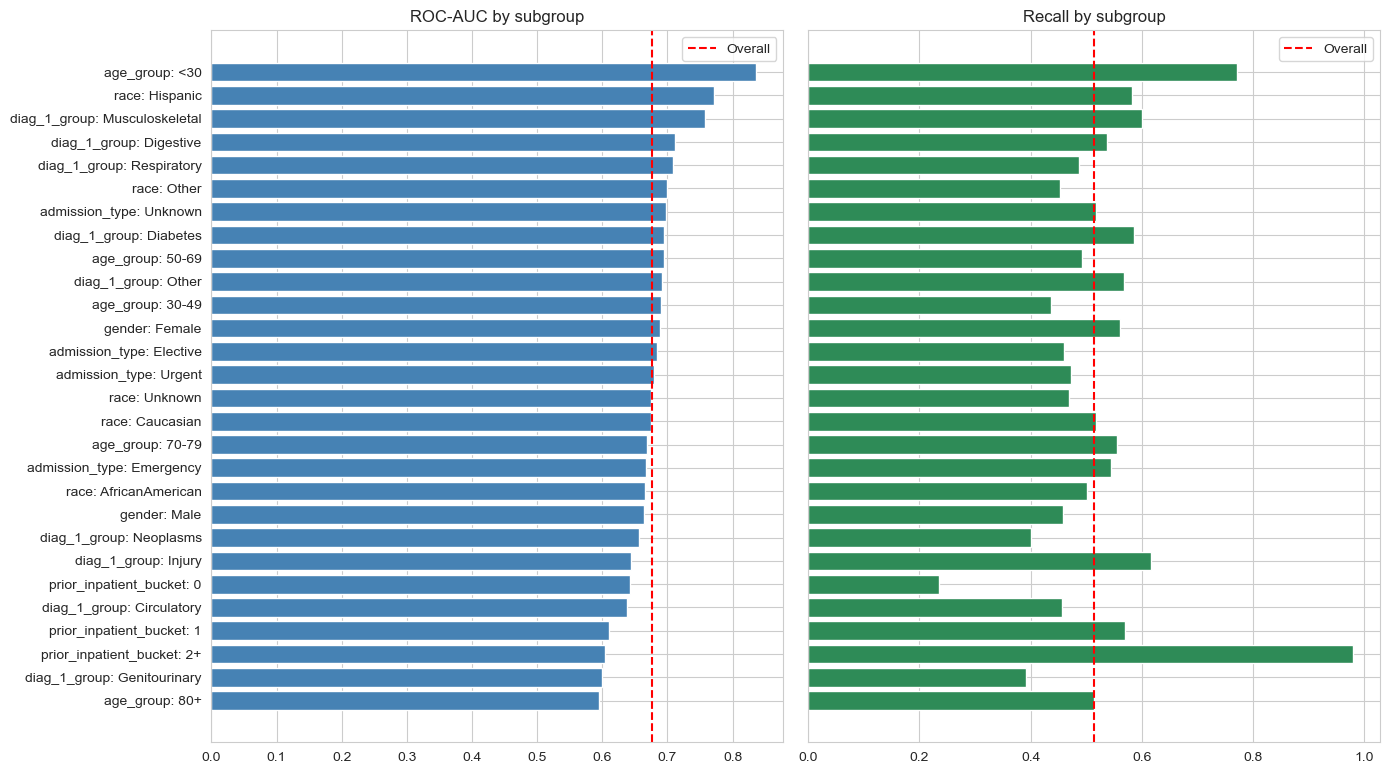

Largest performance gaps within each attribute:


,AUC_min,AUC_max,Recall_min,Recall_max,AUC_gap,Recall_gap
Attribute,,,,,,
admission_type,0.667,0.697,0.460,0.544,0.030,0.084
age_group,0.595,0.836,0.437,0.771,0.241,0.334
diag_1_group,0.599,0.758,0.391,0.617,0.159,0.226
gender,0.664,0.688,0.459,0.561,0.024,0.102
prior_inpatient_bucket,0.604,0.642,0.235,0.979,0.038,0.744
race,0.665,0.771,0.452,0.583,0.106,0.131


In [46]:
plot_df = subgroup_df.copy()
plot_df["label"] = plot_df["Attribute"] + ": " + plot_df["Group"].astype(str)
plot_df = plot_df.sort_values("ROC-AUC")

fig, axes = plt.subplots(1, 2, figsize=(14, max(5, 0.28 * len(plot_df))), sharey=True)
axes[0].barh(plot_df["label"], plot_df["ROC-AUC"], color="steelblue")
axes[0].axvline(final_metrics["ROC-AUC"], color="red", ls="--", label="Overall")
axes[0].set_title("ROC-AUC by subgroup"); axes[0].legend()
axes[1].barh(plot_df["label"], plot_df["Recall"], color="seagreen")
axes[1].axvline(final_metrics["Recall"], color="red", ls="--", label="Overall")
axes[1].set_title("Recall by subgroup"); axes[1].legend()
plt.tight_layout(); plt.show()

print("Largest performance gaps within each attribute:")
gap = subgroup_df.groupby("Attribute").agg(
    AUC_min=("ROC-AUC", "min"), AUC_max=("ROC-AUC", "max"),
    Recall_min=("Recall", "min"), Recall_max=("Recall", "max"))
gap["AUC_gap"] = gap["AUC_max"] - gap["AUC_min"]
gap["Recall_gap"] = gap["Recall_max"] - gap["Recall_min"]
gap.round(3)

**Reading the subgroup results:** compare each subgroup's ROC-AUC and recall with the overall test-set values. Lower ROC-AUC indicates weaker within-group ranking; lower recall indicates a larger share of actual readmissions are missed at the selected threshold. Also check precision, observed prevalence and patient count before drawing conclusions. The red overall reference line is a benchmark, not a fairness threshold. Small groups and groups with few readmissions have noisier estimates.

### 9.7 High-risk patient profiles
We describe who the model flags as **High** risk by (a) comparing flagged patients with the others, (b) checking that readmission rises across risk deciles, (c) mapping actual readmission rates over age and prior inpatient visits, and (d) showing a small, readable decision tree.

In [47]:
test_profile = X_test.reset_index(drop=True).copy()
test_profile["risk"] = test_cal
test_profile["flagged"] = np.where(test_cal >= BEST_THRESHOLD, "High risk", "Not high risk")
test_profile["age_group"] = test_meta["age_group"]
test_profile["readmitted"] = y_test_arr

print(f"High-risk patients: {(test_profile['flagged'] == 'High risk').mean() * 100:.1f}% of test patients\n")

profile_cols = ["age_num", "number_inpatient", "number_emergency", "number_outpatient", "total_prior_visits",
                "time_in_hospital", "num_medications", "number_diagnoses", "n_meds_changed", "readmitted"]
print("Average values, high-risk vs others:")
display(test_profile.groupby("flagged")[profile_cols].mean().T.round(2))

for col in ["diag_1_group", "discharge_group"]:
    share = (pd.crosstab(test_profile[col], test_profile["flagged"], normalize="columns") * 100).round(1)
    print(f"\nShare (%) of each {col} within the two groups:")
    display(share.sort_values("High risk", ascending=False))

High-risk patients: 29.3% of test patients

Average values, high-risk vs others:


flagged,High risk,Not high risk
age_num,69.18,64.17
number_inpatient,1.69,0.17
number_emergency,0.45,0.08
number_outpatient,0.65,0.28
total_prior_visits,2.79,0.53
time_in_hospital,5.31,3.96
num_medications,17.87,15.09
number_diagnoses,8.06,7.12
n_meds_changed,0.40,0.25
readmitted,0.20,0.08



Share (%) of each diag_1_group within the two groups:


flagged,High risk,Not high risk
diag_1_group,,
Circulatory,29.0,30.8
Other,19.4,17.1
Respiratory,11.5,14.8
Injury,10.4,5.3
Diabetes,10.1,8.2
Digestive,8.0,9.9
Genitourinary,5.0,5.1
Musculoskeletal,4.3,5.2
Neoplasms,2.2,3.6



Share (%) of each discharge_group within the two groups:


flagged,High risk,Not high risk
discharge_group,,
Transferred / other care,53.4,7.9
Home,29.5,73.5
Home with health service,12.9,12.6
Unknown,3.6,5.3
Left AMA,0.7,0.7


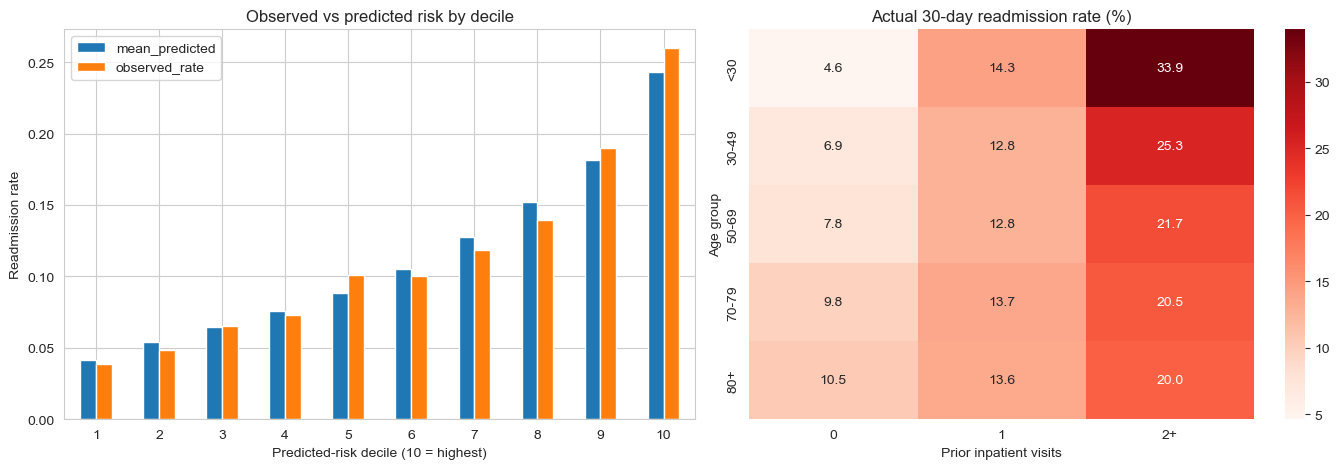

In [48]:
test_profile["decile"] = pd.qcut(test_profile["risk"].rank(method="first"), 10, labels=range(1, 11))
decile = test_profile.groupby("decile").agg(mean_predicted=("risk", "mean"), observed_rate=("readmitted", "mean"))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
decile.plot(kind="bar", ax=axes[0], rot=0)
axes[0].set_xlabel("Predicted-risk decile (10 = highest)"); axes[0].set_ylabel("Readmission rate")
axes[0].set_title("Observed vs predicted risk by decile")

heat = df_model.pivot_table(index="age_group", columns="prior_inpatient_bucket", values="readmit_30", aggfunc="mean")
heat = heat.reindex(["<30", "30-49", "50-69", "70-79", "80+"])[["0", "1", "2+"]] * 100
sns.heatmap(heat, annot=True, fmt=".1f", cmap="Reds", ax=axes[1])
axes[1].set_title("Actual 30-day readmission rate (%)"); axes[1].set_xlabel("Prior inpatient visits"); axes[1].set_ylabel("Age group")
plt.tight_layout(); plt.show()

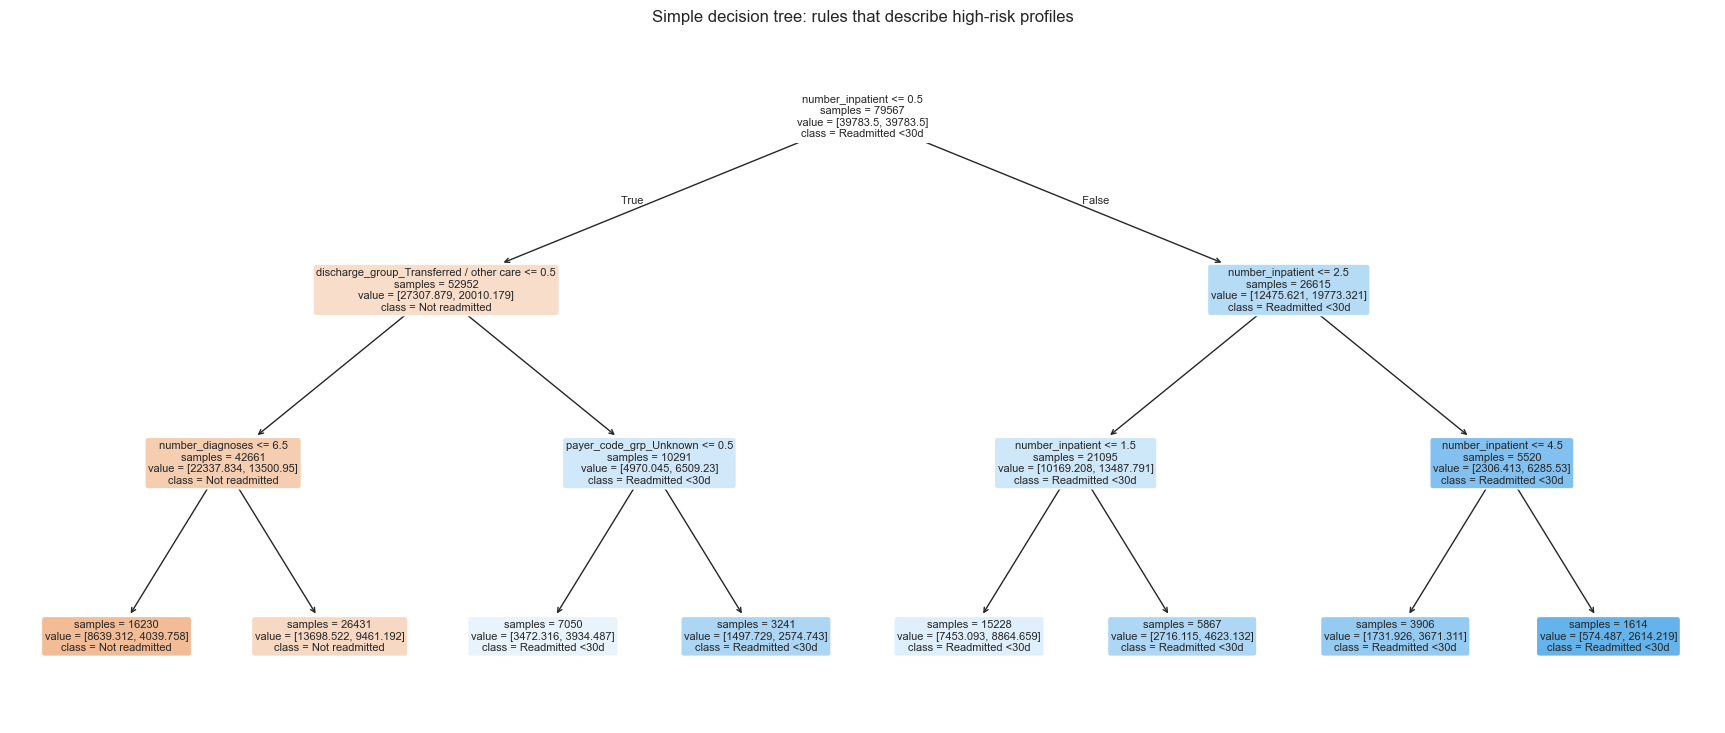

In [49]:
profile_prep = make_preprocessor(scale=False).fit(X_train)
profile_names = [n.split("__", 1)[1] for n in profile_prep.get_feature_names_out()]

profile_tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=200, class_weight="balanced",
                                      random_state=RANDOM_STATE)
profile_tree.fit(profile_prep.transform(X_train), y_train)

plt.figure(figsize=(22, 9))
plot_tree(profile_tree, feature_names=profile_names, class_names=["Not readmitted", "Readmitted <30d"],
          filled=True, rounded=True, fontsize=8, impurity=False)
plt.title("Simple decision tree: rules that describe high-risk profiles"); plt.show()

## 10. Model Saving

We save the **group-calibrated prediction model** and the decision/reporting configuration so the complete ML result can be reproduced. The serialized estimator is the `CalibratedClassifierCV` ensemble fitted with patient-grouped folds; prediction uses its calibrated probabilities directly. We also save the selected model name, feature schema, threshold policies, risk-band cutoffs, preprocessing configuration, test metrics and package version.

No web application, API, frontend or deployment workflow is included in this ML-only notebook.


In [50]:
# Save the group-calibrated ensemble and all decision/reporting metadata.
bundle = {
    "model": calibrated_model,
    "model_name": best_name,
    "features": FEATURES,
    "numeric_features": NUMERIC_FEATURES,
    "categorical_features": CATEGORICAL_FEATURES,
    "calibration": {"method": "sigmoid", "cv": "5-fold GroupKFold by patient_nbr"},
    "threshold": BEST_THRESHOLD,
    "threshold_f1_oof": F1_THRESHOLD,
    "threshold_top20_oof": TOP20_THRESHOLD,
    "base_rate": BASE_RATE,
    "risk_band_cutoffs": {"low_below": min(BASE_RATE, BEST_THRESHOLD),
                          "high_from": BEST_THRESHOLD},
    "preprocessing_config": {
        "keep_meds": KEEP_MEDS, "med_columns": MED_COLUMNS,
        "top_specialties": TOP_SPECIALTIES, "top_payers": TOP_PAYERS,
        "exclude_discharge_ids": EXCLUDE_DISCHARGE_IDS,
        "admission_type_map": ADMISSION_TYPE_MAP, "discharge_group_map": DISCHARGE_GROUP_MAP,
        "source_group_map": SOURCE_GROUP_MAP, "age_midpoint": AGE_MIDPOINT,
    },
    "test_metrics": final_metrics,
    "threshold_comparison": threshold_comparison_df.to_dict(orient="records"),
    "sklearn_version": sklearn.__version__,
}
joblib.dump(bundle, "readmission_model.joblib", compress=3)
joblib.dump(tuned_models, "all_tuned_models.joblib", compress=3)

tuned_results.to_csv("model_comparison.csv")
subgroup_df.to_csv("subgroup_performance.csv", index=False)
importance_df.to_csv("feature_importance.csv", index_label="rank")
threshold_comparison_df.to_csv("threshold_comparison.csv", index=False)

for f in ["readmission_model.joblib", "all_tuned_models.joblib", "model_comparison.csv",
          "subgroup_performance.csv", "feature_importance.csv", "threshold_comparison.csv"]:
    print(f"saved {f:28s} {os.path.getsize(f) / 1e6:8.2f} MB")


saved readmission_model.joblib        32.68 MB
saved all_tuned_models.joblib          7.24 MB
saved model_comparison.csv             0.00 MB
saved subgroup_performance.csv         0.00 MB
saved feature_importance.csv           0.00 MB
saved threshold_comparison.csv         0.00 MB


### 10.1 Reload and test the saved model on raw records

`prepare_encounters` repeats the notebook's cleaning and feature-engineering steps, and `predict_risk` applies the saved pipeline, calibration mapping, threshold and risk bands. The check below takes **raw rows straight from `diabetic_data.csv`** and confirms that the reloaded model reproduces the in-notebook probabilities. This is an ML artefact/reproducibility test only; no frontend, API, hosting or deployment code is included.

In [51]:
def prepare_encounters(raw_df):
    return engineer_features(fill_missing(raw_df))

def predict_risk(raw_df, bundle):
    d = prepare_encounters(raw_df)
    probabilities = bundle["model"].predict_proba(d[bundle["features"]])[:, 1]
    cuts = bundle["risk_band_cutoffs"]
    band = np.where(probabilities >= cuts["high_from"], "High",
                    np.where(probabilities >= cuts["low_below"], "Medium", "Low"))
    return pd.DataFrame({
        "encounter_id": raw_df["encounter_id"].values,
        "risk_probability": probabilities.round(4),
        "risk_band": band,
        "flagged_high_risk": probabilities >= bundle["threshold"]
    })

loaded = joblib.load("readmission_model.joblib")

demo_ids = df_model.iloc[test_idx]["encounter_id"].head(8).tolist()
raw_rows = df_raw[df_raw["encounter_id"].isin(demo_ids)].set_index("encounter_id").loc[demo_ids].reset_index()
demo = predict_risk(raw_rows, loaded)
demo["actual_readmitted_<30d"] = (raw_rows["readmitted"] == "<30").astype(int).values

assert np.allclose(demo["risk_probability"].values, test_cal[:8].round(4), atol=1e-4), "Reloaded model differs!"
print("Reloaded group-calibrated model reproduces the in-notebook predictions.\n")
demo


Reloaded group-calibrated model reproduces the in-notebook predictions.



,encounter_id,risk_probability,risk_band,flagged_high_risk,actual_readmitted_<30d
0,63768,0.0855,Low,False,0
1,84222,0.0506,Low,False,0
2,148530,0.0851,Low,False,0
3,250872,0.0839,Low,False,0
4,326028,0.0457,Low,False,0
5,358776,0.1224,Medium,False,0
6,419304,0.0576,Low,False,0
7,584136,0.0824,Low,False,0


## 11. Key Findings from the Run on the Real Data

*(Numbers below come from the executed run stored in this notebook: `diabetic_data.csv`, `random_state=42`, scikit-learn 1.9. Re-running should reproduce them very closely; small differences can appear with other library versions.)*

**Data.** 101,766 encounters -> **99,340** kept after removing 3 invalid-gender records and 2,423 death / hospice discharges. **11.4 %** are readmitted within 30 days, so always predicting "no" is 88.7 % accurate, which is why accuracy is not used to judge the models.

**Model comparison (test patients, tuned models, default 0.5 cut-off).**

| Model | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|
| Logistic Regression | 0.180 | 0.556 | 0.272 | 0.665 |
| Decision Tree | 0.177 | 0.570 | 0.270 | 0.655 |
| **Random Forest** | **0.186** | **0.577** | **0.282** | **0.677** |

Random Forest is best (also best in grouped cross-validation, which is how it was chosen). Tuning mattered most for the Decision Tree (baseline ROC-AUC 0.526 -> 0.655) because the unrestricted tree overfits badly. The Random Forest also overfits somewhat (train ROC-AUC 0.79 vs test 0.68). The three models are close, which suggests the limit is the information in the data, not the algorithm. A ROC-AUC around 0.65-0.70 is typical for this dataset.

**Calibration and final model.** Balanced class weights inflate probabilities (Brier 0.212); group-aware sigmoid scaling fixes this (Brier 0.096, better than the 0.101 of a constant-rate guess). With the F1-optimal threshold (0.165) the final model reaches **precision 0.23, recall 0.38, F1 0.29, ROC-AUC 0.68**. Risk bands separate patients well: observed readmission is **7.1 % (Low), 13.0 % (Medium), 22.7 % (High)**.

**Contributing factors.** The strongest variables are the **discharge destination** (transfer to another facility / other care raises risk, discharge home lowers it), the **number of prior inpatient visits** and **total prior visits**, followed by the primary diagnosis group, payer code and diabetes-medication variables.

**High-risk profile.** Patients flagged High have on average about **2 prior inpatient visits (vs 0.2)**, a longer stay (5.4 vs 4.1 days), more medications and diagnoses, and **53 % were discharged to a transfer / other-care setting (vs 12 %)**. The profile tree shows the same rules: prior inpatient visits first, then discharge destination. (The `value = [...]` counts inside the tree boxes are class-weighted, not raw patient counts.)

**Subgroup performance - points to report.**
* **Prior inpatient visits drive the model.** Recall is only **0.13 for patients with no prior inpatient visit** but **0.89 for those with 2 or more**. First-time inpatients who are readmitted are mostly missed.
* **Weaker discrimination** for patients aged **80+** (ROC-AUC 0.60) and for primary diagnoses **Genitourinary** (0.60) and **Circulatory** (0.64), versus 0.68 overall.
* Gender (0.67-0.69) and admission type (0.67-0.69) are fairly even. Race ranges from 0.67 to 0.77, but the higher values are for small groups (about 300-400 patients) and are noisy. The `<30` age group (ROC-AUC 0.83) has only ~530 patients and should not be over-interpreted.

## 12. Summary and Limitations

**Deliverables of the ML part:** a cleaned, patient-split dataset; three tuned models (Logistic Regression, Decision Tree, Random Forest) compared on precision, recall, F1 and ROC-AUC; a calibrated final model with a decision threshold and risk bands; ranked contributing factors; subgroup performance; high-risk profiles; and saved artefacts ready for the FastAPI / Streamlit steps.

**Limitations (please state these in the report):**
* Data are from 130 US hospitals, 1999–2008, so results are not representative of today or of other countries. This is an educational prototype, not a clinical tool.
* Readmission is hard to predict from these fields, so moderate ROC-AUC values are normal for this dataset.
* Threshold choice is a trade-off: a lower threshold catches more readmissions but flags more patients who would not return.
* Subgroup results can be noisy for small groups; `race` was used only for auditing, not as an input.
* The PS18 brief says part of its *Expected Output* section was cut off in the supplied image, so confirm the exact deliverables with the faculty.

**Cohort sensitivity.** Section 7.2 compares the primary all-encounter patient-grouped cohort with the learning-guide first-encounter-per-patient cohort. Use the generated `cohort_sensitivity` table when writing the final report; it prints actual cohort sizes, event prevalence, ROC-AUC and PR-AUC from the current run. Differences should be interpreted in light of the distinct prediction populations.

**Calibration fit-size trade-off.** The saved calibrated model intentionally retains the base estimator trained on the patient-grouped cross-validated calibrated ensemble. Refitting it on all training patients without relearning calibration would invalidate the score-to-probability mapping. Section 9.4 documents this decision and the grouped out-of-fold alternative.

**Cohort sensitivity.** Section 7.2 compares the primary all-encounter patient-grouped cohort with the learning-guide first-encounter-per-patient cohort. Use the generated `cohort_sensitivity` table when writing the final report; it prints actual cohort sizes, event prevalence, ROC-AUC and PR-AUC from the current run. Differences should be interpreted in light of the distinct prediction populations.

**Calibration fit-size trade-off.** The saved calibrated model intentionally retains the base estimator trained on the patient-grouped cross-validated calibrated ensemble. Refitting it on all training patients without relearning calibration would invalidate the score-to-probability mapping. Section 9.4 documents this decision and the grouped out-of-fold alternative.

In [52]:
joblib.dump(bundle, "readmission_model.joblib", compress=3)
joblib.dump(tuned_models, "all_tuned_models.joblib", compress=3)

['all_tuned_models.joblib']

In [53]:
import joblib

loaded = joblib.load("readmission_model.joblib")

print("Model loaded successfully!")
print("Model name:", loaded["model_name"])
print("Features:", len(loaded["features"]))

Model loaded successfully!
Model name: Random Forest
Features: 33


In [58]:
# Paste this cell at the END of PS18_Final_ML_Model_Locked.ipynb and run it.
# It exports 100 genuine held-out test patients in the exact raw format
# expected by the FastAPI request schema, plus notebook reference predictions.

import json
import numpy as np
import pandas as pd

# All medication columns used by the notebook's feature engineering.
MED_API_FIELDS = [
    "metformin", "repaglinide", "nateglinide", "chlorpropamide",
    "glimepiride", "acetohexamide", "glipizide", "glyburide",
    "tolbutamide", "pioglitazone", "rosiglitazone", "acarbose",
    "miglitol", "troglitazone", "tolazamide", "insulin",
    "glyburide_metformin", "glipizide_metformin",
    "glimepiride_pioglitazone", "metformin_rosiglitazone",
    "metformin_pioglitazone"
]

# Select 100 UNIQUE patients from the locked patient-grouped test set.
# First collect all held-out test encounters, then retain one encounter
# per patient so the validation sample contains 100 different patients.
test_encounter_ids = df_model.iloc[test_idx]["encounter_id"].tolist()

raw_test = (
    df_raw[df_raw["encounter_id"].isin(test_encounter_ids)]
    .set_index("encounter_id")
    .loc[test_encounter_ids]
    .reset_index()
)

if "patient_nbr" in raw_test.columns:
    raw_test = raw_test.drop_duplicates(subset="patient_nbr", keep="first")

raw_test = raw_test.head(100).reset_index(drop=True)

if len(raw_test) < 100:
    raise ValueError(
        f"Only {len(raw_test)} unique held-out patients were found; "
        "cannot create a 100-patient validation file."
    )

# Generate the reference prediction using the same function and saved bundle
# used by the notebook's final model.
reference = predict_risk(raw_test, loaded).reset_index(drop=True)
actual_labels = (raw_test["readmitted"].astype(str) == "<30").astype(int).tolist()

def clean_value(value, default):
    if pd.isna(value):
        return default
    if isinstance(value, (np.integer,)):
        return int(value)
    if isinstance(value, (np.floating,)):
        return float(value)
    return str(value) if not isinstance(value, (int, float, bool)) else value

cases = []
for i, row in raw_test.iterrows():
    payload = {
        "encounter_id": int(row["encounter_id"]),
        "age": clean_value(row["age"], "[50-60)"),
        "gender": clean_value(row["gender"], "Unknown/Invalid"),
        "time_in_hospital": int(row["time_in_hospital"]),
        "num_lab_procedures": int(row["num_lab_procedures"]),
        "num_procedures": int(row["num_procedures"]),
        "num_medications": int(row["num_medications"]),
        "number_outpatient": int(row["number_outpatient"]),
        "number_emergency": int(row["number_emergency"]),
        "number_inpatient": int(row["number_inpatient"]),
        "number_diagnoses": int(row["number_diagnoses"]),
        "diag_1": clean_value(row["diag_1"], "Missing"),
        "diag_2": clean_value(row["diag_2"], "Missing"),
        "diag_3": clean_value(row["diag_3"], "Missing"),
        "admission_type_id": int(row["admission_type_id"]),
        "discharge_disposition_id": int(row["discharge_disposition_id"]),
        "admission_source_id": int(row["admission_source_id"]),
        "medical_specialty": clean_value(row["medical_specialty"], "Unknown"),
        "payer_code": clean_value(row["payer_code"], "Unknown"),
        "max_glu_serum": clean_value(row["max_glu_serum"], "Not tested"),
        "A1Cresult": clean_value(row["A1Cresult"], "Not tested"),
        "change": clean_value(row["change"], "No"),
        "diabetesMed": clean_value(row["diabetesMed"], "No")
    }

    # Include ALL 21 diabetes-medication columns. The notebook calculates
    # n_meds_active and n_meds_changed from all of them, not only the 8
    # medications retained as individual model features.
    for med in MED_API_FIELDS:
        source_col = med.replace("_", "-") if med in {
            "glyburide_metformin", "glipizide_metformin",
            "glimepiride_pioglitazone", "metformin_rosiglitazone",
            "metformin_pioglitazone"
        } else med
        payload[med] = clean_value(row[source_col], "No")

    cases.append({
        "payload": payload,
        "expected": {
            "encounter_id": int(reference.loc[i, "encounter_id"]),
            "probability": float(reference.loc[i, "risk_probability"]),
            "risk_level": str(reference.loc[i, "risk_band"]),
            "flagged_high_risk": bool(reference.loc[i, "flagged_high_risk"]),
            "actual_readmitted_within_30d": int(actual_labels[i])
        }
    })

with open("api_validation_cases.json", "w", encoding="utf-8") as f:
    json.dump(cases, f, indent=2)

print("Created api_validation_cases.json")
print("Number of held-out test patients:", len(cases))
print("Notebook reference predictions:")
display(pd.DataFrame([c["expected"] for c in cases]))


Created api_validation_cases.json
Number of held-out test patients: 100
Notebook reference predictions:


,encounter_id,probability,risk_level,flagged_high_risk,actual_readmitted_within_30d
0,63768,0.0855,Low,False,0
1,84222,0.0506,Low,False,0
2,148530,0.0851,Low,False,0
3,250872,0.0839,Low,False,0
4,326028,0.0457,Low,False,0
...,...,...,...,...,...
95,4206732,0.0920,Low,False,0
96,4234932,0.0447,Low,False,0
97,4243416,0.0916,Low,False,0
98,4373364,0.0616,Low,False,0
